---
title: "Fischer-Tropsch on cobalt: the Yates-Satterfield rate law (Yates and Satterfield, 1991)"
description: "The cobalt Fischer-Tropsch rate law most reactor models use, its Table V parameters at 220 and 240 C, and whether they carry the apparent activation energy the paper reports."
categories: [sec:C, struct:S1, struct:S2, tier:T1, data:tier4]
date: 2026-11-27
---

# Fischer-Tropsch on cobalt: the Yates-Satterfield rate law

**Catalog ID:** `C2.7` · **Structures:** `S1`, `S2` · **Tier:** T1

Yates and Satterfield (1991) measured the rate of synthesis gas consumption on a
cobalt catalyst in a stirred slurry reactor and chose
$-R_{\mathrm{H_2+CO}} = a P_{\mathrm{H_2}} P_{\mathrm{CO}}/(1 + b P_{\mathrm{CO}})^2$,
fitted at 220 and 240 °C (their Table V). Slurry-reactor models still take these two
parameter pairs as given (`F2.3`). The paper also reports apparent activation energies
of 92.7 and 94.5 kJ/mol. This page asks whether Table V, read at the paper's own
measured partial pressures, gives those activation energies, and with what
uncertainty, using the parameter covariance recovered from the experimental design of
its Figures 1 and 2. It then puts the rate law in the paper's CSTR and in an ideal
plug-flow reactor with pymrm.

In [1]:
# Bootstrap: the pymrm this page was checked with, and the gallery files it was
# published with. Works in a checkout, in CI and on a fresh Colab VM.
GALLERY_REF = "gallery-2026.11.27.11"  # replaced by the release tag at publication
PYMRM = ">=3.4.0,<4"  # equals meta.yaml pymrm_min_version, up to the next major
PAGE = "C2.7-yates-satterfield-fischer-tropsch"  # equals the page directory

import os, sys, urllib.request
from pathlib import Path
_shared = next((p / "shared" for p in (Path.cwd(), *Path.cwd().parents)
                if (p / "shared" / "gallery_bootstrap.py").is_file()), None)
if _shared is None:
    _shared = (Path(os.environ.get("XDG_CACHE_HOME") or Path.home() / ".cache")
               / "pymrm-gallery" / GALLERY_REF)
    _shared.mkdir(parents=True, exist_ok=True)
    urllib.request.urlretrieve(
        "https://raw.githubusercontent.com/computational-chemical-engineering/"
        f"pymrm-gallery/{GALLERY_REF}/shared/gallery_bootstrap.py",
        _shared / "gallery_bootstrap.py")
sys.path.insert(0, str(_shared))
sys.modules.pop("gallery_bootstrap", None)
from gallery_bootstrap import setup
setup(PAGE, PYMRM, GALLERY_REF);  # the semicolon stops the cell echoing the path

In [2]:
import contextlib
import importlib.util
import io
import re
from dataclasses import dataclass, field, replace

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import HTML, Markdown, display
from scipy import stats
from scipy.optimize import minimize_scalar
from gallery_utils import Claims, assert_check_values, cite_data, load_data, load_meta
from pymrm.checks import observed_orders
from model import (R_GAS, PlugFlow, arrhenius, closure, cstr, cstr_wf, design_covariance,
                   design_jacobian, e_app, e_app_limits, e_app_root, fd_jacobian, feed_flow,
                   inv_dT, one_root, outlet_pco, pfr_wf, rate, rate_dpco, sd_e_app,
                   sd_ratio_rho)

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
claims = Claims(PAGE.split("-")[0])
F23 = "F2.3-slurry-bubble-column-ft"


def fill(text, **v):
    """Fill ``<<name:fmt>>`` in ``text`` from ``v``."""
    def sub(m):
        name, _, fmt = m.group(1).partition(":")
        return format(v[name], fmt)
    return re.sub(r"<<([^<>]+)>>", sub, text)


def say(text, **v):
    """Prose whose numbers are written by code, so they cannot drift."""
    display(Markdown(fill(text, **v)))


def show(styler, uuid):
    """Display a styled table with a pinned id, so two runs print the same HTML."""
    display(HTML(styler.set_uuid(uuid).to_html()))


def page_module(page):
    """Import another page's model.py: from the checkout, else from GitHub at GALLERY_REF."""
    src = next((p / "pages" / page / "model.py" for p in (Path.cwd(), *Path.cwd().parents)
                if (p / "pages" / page / "model.py").is_file()), None)
    if src is None:
        src = _shared / f"{page}-model.py"
        urllib.request.urlretrieve(
            "https://raw.githubusercontent.com/computational-chemical-engineering/"
            f"pymrm-gallery/{GALLERY_REF}/pages/{page}/model.py", src)
    spec = importlib.util.spec_from_file_location(page.split("-")[0].replace(".", "_"), src)
    mod = importlib.util.module_from_spec(spec)
    spec.loader.exec_module(mod)
    return mod

## Background

Fischer-Tropsch synthesis on cobalt turns synthesis gas into mostly linear alkanes
and water, $n\,\mathrm{CO} + 2n\,\mathrm{H_2} \to (\mathrm{-CH_2-})_n + n\,\mathrm{H_2O}$
(eq. 1). Cobalt hardly catalyses the water-gas shift, so H2 and CO are used in a
ratio near 2 and one rate describes the synthesis. Yates and Satterfield measured
that rate on a Co/MgO on silica catalyst in a 1 L stirred slurry reactor, "220-240
°C, 0.5-1.5 MPa, H2/CO feed ratios of 1.5-3.5" (abstract, p. 168), a CSTR in which
each run gives the rate at the reactor's own partial pressures. They compared
Langmuir-Hinshelwood forms by linearised plots (Table III) and by nonlinear
regression (Table IV) and chose eq. 16, whose two parameters they fitted at each
temperature (Table V). Its denominator makes CO inhibit its own conversion.

They did not fit an Arrhenius form: "With data from a temperature range of only 20
°C, it was not reasonable to do in the present case." (p. 172). Instead, "an
apparent activation energy was calculated from rate data for two sets of values of
P<sub>H2</sub> and P<sub>CO</sub> that were nearly the same at 220 and 240 °C. The
apparent activation energies were 92.7 and 94.5 kJ/mol" (p. 172). Table V fixes the
same quantity: at one $(P_{\mathrm{H_2}}, P_{\mathrm{CO}})$ the ratio of the two
fitted rates gives an apparent activation energy at fixed partial pressures; the
authors used two pairs of measured rates, whose ratio this is the expected value of,
and single runs add their scatter (below). This page computes it over the range of $P_{\mathrm{CO}}$ that both
temperatures cover, with its standard error, and asks whether 92.7 to 94.5 kJ/mol
lies in that range.

Not covered: the product (chain-length) distribution, which the catalogue line for
this entry mentions but this paper does not contain ("Product compositions obtained
at the same operating conditions will be reported separately", p. 168); the
mass-transfer verification (p. 169); the other authors' data of Figs. 9 to 11; the
230 °C points of Fig. 8, for which no parameters are printed; the linearised forms
of Figs. 3 to 7; and a refit of 240 °C rates rebuilt from Figure 8 (planned, not
done: neither eq. 16 against eq. 7 nor the scatter of the near-identical run pairs is
refitted here).

## The published model

| | equation | source |
|---|---|---|
| eq. 16 | $-R_{\mathrm{H_2+CO}} = \dfrac{a P_{\mathrm{H_2}} P_{\mathrm{CO}}}{(1 + b P_{\mathrm{CO}})^2}$ | p. 171, abstract |
| rivals | eq. 4 $\frac{a P_{\mathrm{H_2}}^2 P_{\mathrm{CO}}}{1 + b P_{\mathrm{H_2}}^2 P_{\mathrm{CO}}}$, eq. 7 $\frac{a P_{\mathrm{H_2}} P_{\mathrm{CO}}^{1/2}}{(1 + b P_{\mathrm{CO}}^{1/2})^3}$, eq. 14 $\frac{a P_{\mathrm{CO}}^{1/2} P_{\mathrm{H_2}}^{1/2}}{(1 + b P_{\mathrm{CO}}^{1/2})^2}$, eq. 15 $\frac{a P_{\mathrm{CO}} P_{\mathrm{H_2}}^{1/2}}{(1 + b P_{\mathrm{CO}})^2}$ | Table I, p. 171 |
| $E_{\mathrm{app}}$ (page) | $\dfrac{R}{D}\left[\ln\dfrac{a_{240}}{a_{220}} + 2\ln\dfrac{1 + b_{220}P_{\mathrm{CO}}}{1 + b_{240}P_{\mathrm{CO}}}\right]$, $D = \dfrac{1}{T_{220}} - \dfrac{1}{T_{240}}$ | from eq. 16 |
| limits | $P_{\mathrm{CO}}\to 0$: $E_a = R\ln(a_{240}/a_{220})/D$; $P_{\mathrm{CO}}\to\infty$: $E_a - 2\Delta H_b$, $\Delta H_b = -R\ln(b_{220}/b_{240})/D$ | from eq. 16 |
| covariance (page) | $C = s^2 (J^{\mathsf T}J)^{-1}$, $J_i = \left[\dfrac{P_{\mathrm{H_2}}P_{\mathrm{CO}}}{(1+bP_{\mathrm{CO}})^2},\ -\dfrac{2aP_{\mathrm{H_2}}P_{\mathrm{CO}}^2}{(1+bP_{\mathrm{CO}})^3}\right]$ at each run | linearised least squares |
| CSTR (page) | $F_{i,0} - F_i - \nu_i W(-R)/(1+U) = 0$, $\nu = (1, U, -1)$ for CO, H2, H2O consumed; $P_i = P F_i/\sum F$ | experimental section |
| PFR (page) | $\mathrm{d}F_i/\mathrm{d}W = -\nu_i(-R)/(1+U)$, same gas | ideal plug flow |

$P_{\mathrm{H_2}}$ cancels from $E_{\mathrm{app}}$. The rate is H2 plus CO consumed
per gram of unreduced catalyst ("The rate of the Fischer-Tropsch reaction is
defined here as the moles of hydrogen plus carbon monoxide converted per time per
mass of unreduced catalyst", p. 168), so CO is consumed at $-R/(1+U)$ with the
usage ratio $U = 2$ (the paper: "This averaged slightly above 2", p. 170). Eqs.
14 to 16 are typeset with $-R_{\mathrm{CO}}$ on the left, but "All equations were
expressed in terms of the rate of hydrogen plus carbon monoxide consumption" (p.
171).

| symbol | code | unit |
|---|---|---|
| $a$, $b$ at 220 and 240 °C | `par["a220"]`, `par["b240"]`, ... | mmol/(min g MPa²), 1/MPa |
| $-R_{\mathrm{H_2+CO}}$ | `rate(a, b, p_h2, p_co)` | mmol/(min g) |
| $E_{\mathrm{app}}(P_{\mathrm{CO}})$, its standard error | `e_app`, `sd_e_app` | kJ/mol |
| $C$ from the design | `design_covariance` | |
| CSTR, PFR | `cstr`, `PlugFlow` (pymrm); closed forms `cstr_wf`, `pfr_wf` | |

## Parameters and assumptions

Every printed number is read as a string from
`yates-satterfield-1991-printed-numbers.csv`, so the page can compare with it in
half-units of its last printed digit. Assumptions: 220 and 240 °C are 493.15 and
513.15 K; $R$ = 8.314462618 J/(mol K); the two temperatures were fitted
independently (no covariance between them); standard conditions for the feed are
273.15 K and 101.325 kPa, which the paper does not define ("Flow is calculated at
standard conditions", Table II, footnote a); in the reactors the gas holds H2, CO and
water only, without inert, at the usage ratio $U = 2$; the reactors are isothermal and
isobaric.

In [3]:
PN = load_data("yates-satterfield-1991-printed-numbers.csv", page=PAGE, dtype=str,
               keep_default_na=False)
print(cite_data(load_meta("yates-satterfield-1991-printed-numbers.csv", page=PAGE)))


def printed(pn, item):
    """A printed entry, as the string printed."""
    return pn.loc[pn["item"] == item, "printed"].iloc[0]


def num(pn, item):
    """A printed number as a float."""
    return float(printed(pn, item))


def half_units(pn, item, x):
    """Distance of a computed value from a printed entry in half-units of its last digit."""
    s = printed(pn, item)
    dec = len(s.split(".")[1]) if "." in s else 0
    return abs(x - float(s)) / (0.5 * 10.0 ** (-dec))


def unit_of(s):
    """Half of the last printed digit of a string entry."""
    dec = len(s.split(".")[1]) if "." in s else 0
    return 0.5 * 10.0 ** (-dec)


tv = PN[PN.source == "Table V"].set_index("item").printed
print("Table V as printed:", ", ".join(f"{k} {v}" for k, v in tv.items()))

Yates, I. C.; Satterfield, C. N. (1991) — Energy & Fuels 5(1) 168-173 — doi:10.1021/ef00025a029 — transcribed
Table V as printed: a_240 75.76, sd_a_240 9.20, t_a_240 8.23, b_240 11.61, sd_b_240 0.97, t_b_240 12.02, a_220 53.11, sd_a_220 1.38, t_a_220 38.63, b_220 22.26, sd_b_220 3.63, t_b_220 6.62


## The data

Three datasets from this paper, each with a provenance sidecar; the two digitised
ones are regenerated by `extract_figures.py` from a local copy of the PDF.

- `yates-satterfield-1991-fig1-fig2-design.csv`: the reactor partial pressures of
  every run, Figure 1 (220 °C) and Figure 2 (240 °C), the design behind Table V.
  Overlapping markers were separated by template matching. Figure 2 shows 22
  triangles for 23 runs (Table V, footnote b): the 23rd lies under one of them, and
  the page carries all 22 placements through the correlation of the 240 °C design, the
  ratio and correlation of the standard errors and the minimum of z.
  Reading error ±0.003 MPa per coordinate (sidecar).
- `yates-satterfield-1991-fig8-parity.csv`: Figure 8, measured against predicted
  rate. Only markers that stand alone are used one by one; four merged pairs and a
  clump below 0.3 mmol/(min g) are recorded but not read individually. Reading error
  ±0.004 mmol/(min g).
- `yates-satterfield-1991-printed-numbers.csv`: Tables II to V, footnotes and stated
  numbers, as strings.

One dataset is borrowed: none. One constant set is imported, never retyped: `F2.3`'s
`PARAMS` (its `model.py`), its two-point Arrhenius form of Table V in SI units, which
the Reuse section checks against this page.

In [4]:
DESIGN = load_data("yates-satterfield-1991-fig1-fig2-design.csv", page=PAGE)
FIG8 = load_data("yates-satterfield-1991-fig8-parity.csv", page=PAGE)
print(cite_data(load_meta("yates-satterfield-1991-fig1-fig2-design.csv", page=PAGE)))
print(cite_data(load_meta("yates-satterfield-1991-fig8-parity.csv", page=PAGE)))
N_VIS = DESIGN.groupby("T_C").size()
say("Digitised: <<n220:d>> runs at 220 °C (Table V: <<p220>>) and <<n240:d>> visible at "
    "240 °C (Table V: <<p240>>); Figure 8: <<ni:d>> isolated markers, <<np:d>> merged "
    "pairs and <<nc:d>> clump.", n220=int(N_VIS[220]), n240=int(N_VIS[240]),
    p220=printed(PN, "n_220"), p240=printed(PN, "n_240"),
    ni=int((FIG8.status == "isolated").sum()), np=int((FIG8.status == "pair").sum()),
    nc=int((FIG8.status == "clump").sum()))
if N_VIS[220] != int(printed(PN, "n_220")) or N_VIS[240] + 1 != int(printed(PN, "n_240")):
    raise ValueError("digitised counts differ from Table V (plan stop rule)")

Yates, I. C.; Satterfield, C. N. (1991) — Energy & Fuels 5(1) 168-173 — doi:10.1021/ef00025a029 — digitised from Figure 1 (220 C) and Figure 2 (240 C), page 170 (PDF page 3)
Yates, I. C.; Satterfield, C. N. (1991) — Energy & Fuels 5(1) 168-173 — doi:10.1021/ef00025a029 — digitised from Figure 8, page 172 (PDF page 5)


Digitised: 17 runs at 220 °C (Table V: 17) and 22 visible at 240 °C (Table V: 23); Figure 8: 13 isolated markers, 4 merged pairs and 1 clump.

## PyMRM implementation

Results R1 to R4 are closed forms and scipy statistics on the printed numbers and
the digitised design; pymrm enters through `pymrm.checks.find_roots` (every root:
where $E_{\mathrm{app}}$ equals a quoted value, the rate maximum as a root of the
analytic derivative, the conversion at which the outlet $P_{\mathrm{CO}}$ leaves the
measured range, the PFR conversion from its closed form). The reactors (R6) are
pymrm models in `model.py`:

- `cstr`: the three species balances of the slurry CSTR (CO, H2, H2O flows scaled by
  the CO feed, shape `(1, 3)`), Jacobian by `NumJac((1, 3))`, one bounded `newton`
  solve with `success` checked;
- `PlugFlow`: the ideal PFR on the scaled catalyst mass $\xi = W/W_{\mathrm{tot}}$,
  the three molar flows on an `(n, 3)` grid convected at unit velocity
  (`construct_convflux_upwind`, first order; `construct_div` with `nu=0`), inlet
  flows fixed at $\xi = 0$, `{"outflow": True}` at $\xi = 1$, the rate as a
  pointwise source through `NumJac((n, 3))`, one `newton` solve; the outlet
  conversion is read from the outlet face with `compute_boundary_values`. The total
  flow changes with conversion, which convecting the flows themselves absorbs.

Every number the page states comes out of one function `study(cfg)`; each break row
below changes one field of `cfg` (a reading of the paper, a printed entry, a unit, a
solver setting) and reruns it.

### Check values

`data/check_values.csv` holds 76 values computed by a second route (the planning
agent's script; scipy, no pymrm, no page code) at one test condition. The page's
functions must reproduce every row before any result is stated.

In [5]:
def params(cfg):
    """Table V and the temperatures, as the study reads them."""
    pn = cfg.pn
    par = {"a240": num(pn, "a_240"), "b240": num(pn, "b_240"),
           "a220": num(pn, "a_220"), "b220": num(pn, "b_220"),
           "T1": 220.0 + cfg.t_off, "T2": 240.0 + cfg.t_off}
    if cfg.swap_b:
        par["b240"], par["b220"] = par["b220"], par["b240"]
    return par


def tab2(pn, k):
    return {c: num(pn, f"tab2_row{k}_{c}") for c in ("R", "PH2", "PCO")}


def check_values_t(cfg):
    """Table V and footnote arithmetic: t values, allowances, critical t, printed ratios."""
    pn, M = cfg.pn, {}
    for nm, est, sd, t in (("a240", "a_240", "sd_a_240", "t_a_240"),
                           ("b240", "b_240", "sd_b_240", "t_b_240"),
                           ("a220", "a_220", "sd_a_220", "t_a_220"),
                           ("b220", "b_220", "sd_b_220", "t_b_220"),
                           ("b220_sd336", "b_220", None, "t_b_220")):
        e = num(pn, est)
        s_str = printed(pn, sd) if sd else "3.36"
        s = float(s_str)
        tc = e / s
        allow = tc * (unit_of(printed(pn, est)) / e + unit_of(s_str) / s) + unit_of(printed(pn, t))
        M[f"r2_t_{nm}"] = tc
        M[f"r2_allow_{nm}"] = abs(num(pn, t) - tc) / allow
    for T, df in ((240, 21), (220, 15)):
        tc = stats.t.ppf(cfg.tcrit_q, df)
        M[f"r2_tcrit_{T}"], M[f"r2_tcrit_{T}_half_units"] = tc, half_units(pn, f"tcrit_{T}", tc)
    M["r2_ratio_240_printed"] = num(pn, "sd_a_240") / num(pn, "sd_b_240")
    M["r2_ratio_220_printed"] = num(pn, "sd_a_220") / num(pn, "sd_b_220")
    return M


def check_values(cfg):
    """The page's value for every row of check_values.csv."""
    pn, par = cfg.pn, params(cfg)
    m = check_values_t(cfg)
    cv = {}
    for nm in ("a240", "b240", "a220", "b220", "b220_sd336"):
        cv[f"t_{nm}_computed"], cv[f"t_{nm}_allowance_ratio"] = m[f"r2_t_{nm}"], m[f"r2_allow_{nm}"]
    cv["tcrit_0995_21"], cv["tcrit_21_half_units"] = m["r2_tcrit_240"], m["r2_tcrit_240_half_units"]
    cv["tcrit_0995_15"], cv["tcrit_15_half_units"] = m["r2_tcrit_220"], m["r2_tcrit_220_half_units"]
    cv["sd_ratio_a_over_b_240_printed"] = m["r2_ratio_240_printed"]
    cv["sd_ratio_a_over_b_220_printed"] = m["r2_ratio_220_printed"]
    lo, hi, sst = tab4_sst(pn)
    cv["tab4_SST_lower"], cv["tab4_SST_upper"] = lo, hi
    for e in (4, 7, 14, 15, 16):
        cv[f"tab4_SST_eq{e}"] = sst[e]
    for e in (4, 7, 14, 15):
        cv[f"tab4_SSE_ratio_eq{e}_over_eq16"] = num(pn, f"tab4_eq{e}_SSE") / num(pn, "tab4_eq16_SSE")
    ea, dhb, ta, tb = arrhenius(par)
    cv["Ea_of_a_kJ"], cv["dH_of_b_kJ"], cv["Ta_of_a_K"], cv["Tb_of_b_K"] = ea, dhb, ta, tb
    s = tab2(pn, 1)
    cv["E_app_S_kJ"] = float(e_app(s["PCO"], par))
    cv["E_app_limit_P0_kJ"], cv["E_app_limit_Pinf_kJ"] = e_app_limits(par)
    r240 = rate(par["a240"], par["b240"], s["PH2"], s["PCO"])
    r220 = rate(par["a220"], par["b220"], s["PH2"], s["PCO"])
    d = inv_dT(par)
    for eq, item in (("92.7", "E_app_1"), ("94.5", "E_app_2")):
        eq_v = num(pn, item)
        cv[f"pco_where_E_app_{eq}_MPa"] = e_app_root(eq_v, par)
        cv[f"ph2_ratio_needed_S_for_{eq}"] = (r240 / r220) / np.exp(eq_v * 1e3 * d / R_GAS)
    cv["rate_240_S"], cv["rate_220_S"], cv["rate_ratio_S"] = r240, r220, r240 / r220
    cv["rate_ratio_for_94.5"] = np.exp(num(pn, "E_app_2") * 1e3 * d / R_GAS)
    for T in (240, 220):
        b = par[f"b{T}"]
        th = b * s["PCO"] / (1 + b * s["PCO"])
        cv[f"theta_{T}_S"], cv[f"order_CO_{T}_S"] = th, (1 - b * s["PCO"]) / (1 + b * s["PCO"])
        cv[f"pco_rate_max_{T}"] = one_root(lambda p: rate_dpco(par[f"a{T}"], b, s["PH2"], p),
                                           1e-4, 1.0, "rate maximum")
        cv[f"rate_max_{T}_ph2_048"] = rate(par[f"a{T}"], b, s["PH2"], cv[f"pco_rate_max_{T}"])
    for k in (1, 2, 3, 4):
        r = tab2(pn, k)
        cv[f"tab2_row{k}_model_minus_measured"] = rate(par["a240"], par["b240"], r["PH2"], r["PCO"]) - r["R"]
    cv["a220_SI_mol_s_kg_bar2"] = par["a220"] / 6000.0
    check_values_reactor(cfg, par, cv)
    return cv


def check_values_reactor(cfg, par, cv):
    """The closure, CSTR and PFR rows of check_values.csv."""
    pn, d = cfg.pn, inv_dT(par)
    P, q, m = num(pn, "tab2_P"), num(pn, "tab2_q"), num(pn, "tab2_m")
    for suf, tstd in (("", 273.15), ("_25C", 298.15)):
        cv[f"feed_syngas_mmol_min_g{suf}"] = feed_flow(q, tstd)
        ph2, pco, x = closure(tab2(pn, 1)["R"], q, m, P, 2.0, tstd)
        cv[f"closure_row1_PH2{suf}"], cv[f"closure_row1_PCO{suf}"], cv[f"closure_row1_XCO{suf}"] = ph2, pco, x
    ph2, pco, _ = closure(tab2(pn, 3)["R"], num(pn, "tab2_row3_q"), num(pn, "tab2_row3_m"), P)
    cv["closure_row3_PH2"], cv["closure_row3_PCO"] = ph2, pco
    tau = (1 + m) / feed_flow(q)
    c240 = cstr(par["a240"], par["b240"], P, tau)
    cv["cstr240_X"], cv["cstr240_rate"] = c240["X"], c240["rate"]
    cv["cstr240_PCO"], cv["cstr240_PH2"] = c240["P_CO"], c240["P_H2"]
    cv["cstr220_X"] = cstr(par["a220"], par["b220"], P, tau)["X"]
    k945 = np.exp(num(pn, "E_app_2") * 1e3 * d / R_GAS)
    cv["cstr220_from240_E94.5_X"] = cstr(par["a240"] / k945, par["b240"], P, tau)["X"]
    cv["cstr220_rate_ratio_E94.5_over_tableV"] = cv["cstr220_from240_E94.5_X"] / cv["cstr220_X"]
    cv["pfr240_X"] = one_root(lambda x: pfr_wf(x, par["a240"], par["b240"], P) - tau,
                              1e-9, 1 - 1e-9, "PFR conversion")
    x5 = 0.5
    cv["wf_cstr_over_pfr_240_X0.5"] = (cstr_wf(x5, par["a240"], par["b240"], P)
                                       / pfr_wf(x5, par["a240"], par["b240"], P))
    for sv in ("0.085", "0.008"):
        cv[f"cstr240_X_sv{sv}"] = cstr(par["a240"], par["b240"], P, (1 + m) / feed_flow(float(sv)))["X"]


def tab4_sst(pn, from_r2=False):
    """Table IV: SST = SSE/(1 - R^2) per row and the interval all rows allow by rounding."""
    sst, lo, hi = {}, [], []
    for e in (4, 7, 14, 15, 16):
        s_s, r_s = printed(pn, f"tab4_eq{e}_SSE"), printed(pn, f"tab4_eq{e}_R2")
        s, r2, us, ur = float(s_s), float(r_s), unit_of(s_s), unit_of(r_s)
        f = (lambda r: r) if from_r2 else (lambda r: 1.0 - r)
        sst[e] = s / f(r2)
        ends = [(s + ds) / f(r2 + dr) for ds in (-us, us) for dr in (-ur, ur)]
        lo.append(min(ends))
        hi.append(max(ends))
    return max(lo), min(hi), sst


@dataclass(frozen=True)
class Cfg:
    """Everything the study reads; every break row changes one field."""
    pn: object = field(default_factory=lambda: PN)
    log: object = np.log            # logarithm in E_app
    t_off: float = 273.15           # kelvin offset
    swap_b: bool = False            # b220 and b240 exchanged
    p_scale: float = 1.0            # pressure unit factor entering eq. 16 (10: bar)
    tcrit_q: float = 0.995          # quantile of the critical t
    rho_zero: bool = False          # a-b covariance dropped in sd_E
    hidden: str = "each"            # 23rd marker of Figure 2: "each" placement or "drop"
    sst_r2: bool = False            # Table IV SST from R^2 in place of 1 - R^2
    rate_is_co: bool = False        # eq. 16 read as a CO rate in the reactors
    t_std: float = 273.15           # standard temperature of the feed
    u_ratio: float = 2.0            # H2/CO usage ratio
    swap_figs: bool = False         # Figures 1 and 2 exchanged
    b_col: float = 1.0              # factor on the analytic b-sensitivity
    lim_k: float = 2.0              # factor of dH_b in the P -> inf limit
    read_err: float = 0.003         # MPa, design reading error (Monte Carlo)
    tau_defect: float = 0.0         # PFR tau times (1 + c n^-1/2), a grid-dependent defect
    comp_tau: float = 1.0           # tau factor of the PFR round-off companion
    feed_scale: float = 1.0         # PFR feed factor in the order study
    ladder: tuple = (50, 100, 200, 400, 800)
    n_draws: int = 200              # Monte Carlo draws per seed
    vif_power: float = 2.0          # variance inflation 1/(1 - r^power)
    fig8_pairs: bool = False        # Figure 8 pairs counted as two markers at their centroid


C0 = Cfg()
with contextlib.redirect_stdout(io.StringIO()):
    DEV = assert_check_values(check_values(C0), page=PAGE)
say("Check values: <<n:d>> of <<t:d>> rows agree, each inside its own tolerance (rtol 1e-11 "
    "to 1e-7); worst relative deviation <<w:.1e>>.",
    n=sum(abs(v) <= r for v, r in zip(DEV.values(), load_data("check_values.csv", page=PAGE).rtol)),
    t=len(DEV), w=max(abs(v) for v in DEV.values()))

Check values: 76 of 76 rows agree, each inside its own tolerance (rtol 1e-11 to 1e-7); worst relative deviation 4.8e-12.

### The study

In [6]:
N_SEEDS = 12
NZ = 401                                     # scan points of z over the common range


def designs(cfg):
    """Digitised designs per temperature, in the units eq. 16 reads.

    Returns ``{220: [(pco, ph2)], 240: [(pco, ph2), ...], "vis": {T: (pco, ph2)}}``: one
    design at 220 C; at 240 C one per placement of the hidden 23rd marker (or the 22
    visible alone); and the visible markers.
    """
    out = {}
    for T in (220, 240):
        g = DESIGN[DESIGN.T_C == ((460 - T) if cfg.swap_figs else T)]
        out[T] = (g.P_CO_MPa.to_numpy() * cfg.p_scale, g.P_H2_MPa.to_numpy() * cfg.p_scale)
    out["vis"] = {T: out[T] for T in (220, 240)}         # the visible markers
    pco, ph2 = out[240]
    out[240] = ([(pco, ph2)] if cfg.hidden == "drop"
                else [(np.append(pco, pco[i]), np.append(ph2, ph2[i])) for i in range(len(pco))])
    out[220] = [out[220]]
    return out


def z_curve(p, par, c240, c220, eq, rho_zero, log):
    """One-sample z of a quoted E against E_app(P) and its standard error."""
    sd = sd_e_app(p, par, c240, c220, rho_zero=rho_zero)
    return (e_app(p, par, log=log) - eq) / sd, sd


def z_min(par, c240, c220, eq, lo, hi, rho_zero, log, refine=True):
    """Minimum z over [lo, hi]: scan, then bounded minimisation around the scan minimum."""
    p = np.linspace(lo, hi, NZ)
    z, _ = z_curve(p, par, c240, c220, eq, rho_zero, log)
    k = int(np.argmin(z))                   # scan minimum, refined below
    if not refine:
        return float(z[k]), float(p[k])
    a_, b_ = p[max(k - 1, 0)], p[min(k + 1, NZ - 1)]
    r = minimize_scalar(lambda q: z_curve(q, par, c240, c220, eq, rho_zero, log)[0],
                        bounds=(a_, b_), method="bounded", options={"xatol": 1e-12})
    return (float(r.fun), float(r.x)) if r.fun < z[k] else (float(z[k]), float(p[k]))


def part_design(cfg, M):
    """R1 and R2: the design, Table V's t values and the design covariance."""
    pn, par = cfg.pn, params(cfg)
    D = designs(cfg)
    pco, ph2 = D[220][0]
    M["r1_n_220"] = int(pco.size)
    M["r1_n_240"] = int(D[240][0][0].size)
    for T in (220, 240):
        pc, ph = D["vis"][T]
        M[f"r1_pco_lo_{T}"], M[f"r1_pco_hi_{T}"] = float(pc.min()), float(pc.max())
        r, p = stats.pearsonr(pc, ph)
        rl = stats.pearsonr(np.log(pc), np.log(ph))[0]
        M[f"r1_r_{T}"], M[f"r1_p_{T}"], M[f"r1_vif_log_{T}"] = float(r), float(p), 1.0 / (1.0 - abs(rl) ** cfg.vif_power)
    rr_, pp_ = zip(*(stats.pearsonr(*d_) for d_ in D[240]))
    M["r1_r_240_lo"], M["r1_r_240_hi"] = float(min(rr_)), float(max(rr_))
    M["r1_p_240_lo"], M["r1_p_240_hi"] = float(min(pp_)), float(max(pp_))
    # Table V arithmetic (the check-value functions) at this cfg
    cv = check_values_t(cfg)
    M.update(cv)
    # design covariance: sd ratio and correlation
    ratios, rhos = [], []
    for pc, ph in D[240]:
        rr, rh = sd_ratio_rho(design_covariance(par["a240"], par["b240"], ph, pc, b_col=cfg.b_col))
        ratios.append(rr)
        rhos.append(rh)
    M["r2_ratio_240_lo"], M["r2_ratio_240_hi"] = min(ratios), max(ratios)
    M["r2_rho_240_lo"], M["r2_rho_240_hi"] = min(rhos), max(rhos)
    r220, rho220 = sd_ratio_rho(design_covariance(par["a220"], par["b220"], ph2, pco, b_col=cfg.b_col))
    M["r2_ratio_220"], M["r2_rho_220"] = r220, rho220
    M["r2_factor_220"] = r220 / M["r2_ratio_220_printed"]
    for tag, sdb in (("", num(pn, "sd_b_220")), ("_sd336", 3.36)):
        M[f"r2_sd_a220_design{tag}"] = r220 * sdb
        M[f"r2_t_a220_design{tag}"] = par["a220"] / (r220 * sdb)
    j_a = design_jacobian(par["a240"], par["b240"], *D[240][0][::-1], b_col=cfg.b_col)
    j_f = fd_jacobian(par["a240"], par["b240"], *D[240][0][::-1])
    M["v3_jac_gap"] = float(np.max(np.abs(j_a - j_f) / np.max(np.abs(j_f), axis=0)))
    return D


def covs(cfg, par, D, i240):
    """Covariances at 240 C (placement i240) and 220 C, scaled to the printed sd of b."""
    pc, ph = D[240][i240]
    c240 = design_covariance(par["a240"], par["b240"], ph, pc, sd_b=num(cfg.pn, "sd_b_240"), b_col=cfg.b_col)
    pc, ph = D[220][0]
    c220 = design_covariance(par["a220"], par["b220"], ph, pc, sd_b=num(cfg.pn, "sd_b_220"), b_col=cfg.b_col)
    return c240, c220


def part_eapp(cfg, M, D):
    """R3: E_app over the common measured range, the roots, z from the design covariance."""
    pn, par = cfg.pn, params(cfg)
    log = cfg.log
    ea, dhb, ta, tb = arrhenius(par, log)
    M["r3_Ea"], M["r3_dHb"], M["r3_Ta"], M["r3_Tb"] = ea, dhb, ta, tb
    s = tab2(pn, 1)
    M["r3_E_S"] = float(e_app(s["PCO"] * cfg.p_scale, par, log=log))
    M["r3_E_lim0"], M["r3_E_liminf"] = ea, ea - cfg.lim_k * dhb
    M["v2_liminf_gap"] = abs(float(e_app(1e9, par, log=log)) - M["r3_E_liminf"])
    lo = max(M["r1_pco_lo_220"], M["r1_pco_lo_240"])
    hi = min(M["r1_pco_hi_220"], M["r1_pco_hi_240"])
    M["r3_common_lo"], M["r3_common_hi"] = lo, hi
    M["r3_band_lo"], M["r3_band_hi"] = float(e_app(lo, par, log=log)), float(e_app(hi, par, log=log))
    lowest = min(M["r1_pco_lo_220"], M["r1_pco_lo_240"])
    d = inv_dT(par)
    r240 = rate(par["a240"], par["b240"], s["PH2"] * cfg.p_scale, s["PCO"] * cfg.p_scale)
    r220 = rate(par["a220"], par["b220"], s["PH2"] * cfg.p_scale, s["PCO"] * cfg.p_scale)
    gaps = []
    for tag, item in (("927", "E_app_1"), ("945", "E_app_2")):
        eq = num(pn, item)
        closed = e_app_root(eq, par)
        e0, einf = e_app_limits(par, log)
        if not min(e0, einf) < eq < max(e0, einf):
            # E_app is monotonic between its closed-form limits: no root on (0, inf)
            M["_noroot"], root = True, np.nan
        else:
            root = one_root(lambda p: float(e_app(p, par, log=log)) - eq, 1e-6,
                            1.5 * cfg.p_scale, "E_app root")
            gaps.append(abs(root / closed - 1.0))
        M[f"r3_root_{tag}"] = root
        M[f"r3_lowest_over_root_{tag}"] = lowest / root
        M[f"r3_ph2_ratio_{tag}"] = (r240 / r220) / np.exp(eq * 1e3 * d / R_GAS)
    M["v2_root_gap"] = max(gaps) if gaps else np.nan
    # the rate maximum at fixed P_H2: a root of the analytic derivative, below every run
    for T in (240, 220):
        a, b = par[f"a{T}"], par[f"b{T}"]
        pm = one_root(lambda p: rate_dpco(a, b, s["PH2"] * cfg.p_scale, p), 1e-4 * cfg.p_scale,
                      1.0 * cfg.p_scale, "rate maximum")
        M[f"r3_pmax_{T}"] = pm
        M[f"r3_pmax_{T}_over_lowest"] = pm / M[f"r1_pco_lo_{T}"]
        M[f"v2_pmax_gap_{T}"] = abs(pm * b - 1.0)
    part_z(cfg, M, D, par, lo, hi)
    # G2: printed 240 C ratio inside the design band
    M["r2_g2_margin"] = min(M["r2_ratio_240_printed"] - M["r2_ratio_240_lo"],
                            M["r2_ratio_240_hi"] - M["r2_ratio_240_printed"])


def part_z(cfg, M, D, par, lo, hi):
    """R3: z of the quoted values over [lo, hi] from the design covariance, and its variants."""
    pn, log = cfg.pn, cfg.log
    # z over the common range, every placement of the hidden marker; the smallest is kept
    eq = num(pn, "E_app_2")
    zs = [z_min(par, *covs(cfg, par, D, i), eq, lo, hi, cfg.rho_zero, log, refine=False)[0]
          for i in range(len(D[240]))]
    i_min = int(np.argmin(zs))
    M["_i_min"] = i_min
    c240, c220 = covs(cfg, par, D, i_min)
    z, p_at = z_min(par, c240, c220, eq, lo, hi, cfg.rho_zero, log)
    M["r3_z_945"], M["r3_p_at_min"] = z, p_at
    M["r3_p_at_min_over_lo"] = p_at / lo
    dp = 1e-6 * (hi - lo)               # slope of z at the lower end, relative to z
    zl = z_curve(np.array([lo, lo + dp]), par, c240, c220, eq, cfg.rho_zero, log)[0]
    M["r3_dz_lo_rel"] = float((zl[1] - zl[0]) / dp * (hi - lo) / abs(zl[0]))
    M["r3_sdE_at_min"] = float(sd_e_app(p_at, par, c240, c220, rho_zero=cfg.rho_zero))
    M["r3_z_945_spread_placements"] = max(zs) - min(zs)
    M["r3_z_927"] = z_min(par, c240, c220, num(pn, "E_app_1"), lo, hi, cfg.rho_zero, log)[0]
    pair_z(cfg, M, D, par, i_min, c240, c220, eq)
    M["r3_z_945_rho0"], p0 = z_min(par, c240, c220, eq, lo, hi, True, log)
    M["r3_sdE_rho0"] = float(sd_e_app(p0, par, c240, c220, rho_zero=True))
    c220b = c220 * (3.36 / num(pn, "sd_b_220")) ** 2
    M["r3_z_945_sd336"] = z_min(par, c240, c220b, eq, lo, hi, cfg.rho_zero, log)[0]


def pair_z(cfg, M, D, par, i240, c240, c220, eq):
    """z of a quoted E against the one pair of measured rates behind it (p. 172).

    The pair is the 220/240 C pair of runs closest in (P_CO, P_H2). A quoted E is a ratio of
    the two single rates, so it carries their scatter: s_T from the printed sd_b with the
    design, or at 240 C from Table IV's SSE; the fitted-curve error of E_app is added.
    """
    pn = cfg.pn
    (c2, h2), (c4, h4) = D[220][0], D[240][i240]
    dist = np.hypot(c2[:, None] - c4[None, :], h2[:, None] - h4[None, :])
    j, k = np.unravel_index(int(np.argmin(dist)), dist.shape)
    M["r3_pair_dist"] = float(dist[j, k])
    r = {220: float(rate(par["a220"], par["b220"], h2[j], c2[j])),
         240: float(rate(par["a240"], par["b240"], h4[k], c4[k]))}
    s = {}
    for T, (pc, ph) in ((220, (c2, h2)), (240, (c4, h4))):
        ju = design_covariance(par[f"a{T}"], par[f"b{T}"], ph, pc, b_col=cfg.b_col)
        s[T] = num(pn, f"sd_b_{T}") / np.sqrt(ju[1, 1])
    s_tab4 = np.sqrt(num(pn, "tab4_eq16_SSE") / (int(num(pn, "n_240")) - 2))
    rd = R_GAS / 1e3 / abs(inv_dT(par))
    p = 0.5 * (c2[j] + c4[k])
    e = float(e_app(p, par, log=cfg.log))
    sd_c = float(sd_e_app(p, par, c240, c220, rho_zero=cfg.rho_zero))
    sd_pair = rd * np.hypot(s[240] / r[240], s[220] / r[220])
    sd_pair4 = rd * np.hypot(s_tab4 / r[240], s[220] / r[220])
    M["r3_sd_pair"] = float(sd_pair)
    M["r3_z_945_pair"] = (e - eq) / np.hypot(sd_c, sd_pair)
    M["r3_z_945_pair_tab4"] = (e - eq) / np.hypot(sd_c, sd_pair4)


def part_mc(cfg, M, D):
    """Monte Carlo of the design reading error: spread of the design-dependent numbers.

    Every coordinate of the design moves by a normal error of ``cfg.read_err``; for the
    p values the spread is that of ln p.
    """
    par = params(cfg)
    eq = num(cfg.pn, "E_app_2")
    base = {220: D[220][0], 240: D[240][M["_i_min"]]}
    per_seed = []
    for seed in range(N_SEEDS):
        rng = np.random.default_rng(1000 + seed)
        rows = []
        for _ in range(cfg.n_draws):
            d = {T: tuple(v + rng.normal(0.0, cfg.read_err * cfg.p_scale, v.size) for v in base[T])
                 for T in (220, 240)}
            c240 = design_covariance(par["a240"], par["b240"], d[240][1], d[240][0],
                                     sd_b=num(cfg.pn, "sd_b_240"), b_col=cfg.b_col)
            c220 = design_covariance(par["a220"], par["b220"], d[220][1], d[220][0],
                                     sd_b=num(cfg.pn, "sd_b_220"), b_col=cfg.b_col)
            lo = max(d[220][0].min(), d[240][0].min())
            hi = min(d[220][0].max(), d[240][0].max())
            z, p_at = z_min(par, c240, c220, eq, lo, hi, cfg.rho_zero, cfg.log, refine=False)
            z0, p0 = z_min(par, c240, c220, eq, lo, hi, True, cfg.log, refine=False)
            ju = design_covariance(par["a240"], par["b240"], d[240][1], d[240][0], b_col=cfg.b_col)
            r_ = rate(par["a240"], par["b240"], d[240][1], d[240][0])
            row = {"r2_ratio_240": sd_ratio_rho(c240)[0], "r2_ratio_220": sd_ratio_rho(c220)[0],
                   "r2_rho_240": sd_ratio_rho(c240)[1], "r2_rho_220": sd_ratio_rho(c220)[1],
                   "r3_z_945": z, "r3_z_927": z_min(par, c240, c220, num(cfg.pn, "E_app_1"), lo,
                                                    hi, cfg.rho_zero, cfg.log, refine=False)[0],
                   "r3_sdE_at_min": float(sd_e_app(p_at, par, c240, c220, rho_zero=cfg.rho_zero)),
                   "r3_z_945_rho0": z0,
                   "r3_sdE_rho0": float(sd_e_app(p0, par, c240, c220, rho_zero=True)),
                   "r3_band_lo": float(e_app(lo, par, log=cfg.log)),
                   "r3_band_hi": float(e_app(hi, par, log=cfg.log)),
                   "r4_sse_implied_240": num(cfg.pn, "sd_b_240") ** 2 / ju[1, 1] * 21,
                   "r4_spread_240": float(np.sum((r_ - r_.mean()) ** 2))}
            for T in (220, 240):
                r, pv = stats.pearsonr(*d[T])
                rl = stats.pearsonr(np.log(d[T][0]), np.log(d[T][1]))[0]
                row.update({f"r1_r_{T}": r, f"r1_p_{T}": np.log(pv), f"r1_vif_log_{T}": 1 / (1 - rl ** 2)})
            rows.append([row[k] for k in MC_KEYS])
        per_seed.append(np.std(np.array(rows), axis=0, ddof=1))
    per_seed = np.array(per_seed)
    for k, nm in enumerate(MC_KEYS):
        M[f"mc_sd_{nm}"] = float(per_seed[:, k].mean())
        M[f"mc_sd_{nm}_seed_spread"] = float(per_seed[:, k].std(ddof=1))


MC_KEYS = ("r2_ratio_240", "r2_ratio_220", "r2_rho_240", "r2_rho_220", "r3_z_945", "r3_z_927",
           "r3_sdE_at_min", "r3_z_945_rho0", "r3_sdE_rho0", "r3_band_lo", "r3_band_hi",
           "r4_sse_implied_240", "r4_spread_240", "r1_r_220", "r1_p_220", "r1_vif_log_220",
           "r1_r_240", "r1_p_240", "r1_vif_log_240")


FIG8_ERR, DESIGN_ERR = 0.004, 0.003      # sidecar reading errors: mmol/(min g), MPa


def part_r4(cfg, M, D):
    """R4: Table V against Figure 8, Table II, Table IV and the scatter its sd imply."""
    pn, par = cfg.pn, params(cfg)
    # Figure 8: the top isolated triangles and the two squares, by rank
    for T, sym, k in ((240, "triangle", 4), (220, "square", 2)):
        pc, ph = D[T][M["_i_min"] if T == 240 else 0]
        model = np.sort(rate(par[f"a{T}"], par[f"b{T}"], ph, pc))[::-1][:k]
        f8 = FIG8[FIG8.symbol == sym].sort_values("R_pred", ascending=False)
        if not (f8.status.iloc[:k] == "isolated").all():
            raise ValueError("Figure 8: a top marker is not isolated")
        a, b = par[f"a{T}"], par[f"b{T}"]
        idx = np.argsort(rate(a, b, ph, pc))[::-1][:k]
        r_ = rate(a, b, ph[idx], pc[idx])
        tol = np.sqrt(FIG8_ERR ** 2 + (rate_dpco(a, b, ph[idx], pc[idx]) * DESIGN_ERR) ** 2
                      + (r_ / ph[idx] * DESIGN_ERR) ** 2)
        M[f"r4_fig8_dev_{T}"] = f8.R_pred.to_numpy()[:k] - model
        M[f"r4_fig8_tol_{T}"] = tol
    # Table III: the temperatures at which eq. 21 has the highest R^2 of the linearised forms
    best = []
    for T in (220, 240):
        r2 = {e: num(pn, f"tab3_eq{e}_{T}") for e in range(17, 22)}
        best.append(max(r2, key=r2.get) == 21)
        M[f"r4_tab3_eq21_{T}"], M[f"r4_tab3_eq20_{T}"] = r2[21], r2[20]
    M["r4_tab3_eq21_best_count"] = int(sum(best))
    # Table II at 240 C
    for k in (1, 2, 3, 4):
        r = tab2(pn, k)
        M[f"r4_tab2_res_{k}"] = rate(par["a240"], par["b240"], r["PH2"] * cfg.p_scale,
                                     r["PCO"] * cfg.p_scale) - r["R"]
    # Table IV
    lo, hi, sst = tab4_sst(pn, from_r2=cfg.sst_r2)
    M["r4_sst_lo"], M["r4_sst_hi"] = lo, hi
    for e in (4, 7, 14, 15, 16):
        M[f"r4_sst_eq{e}"] = sst[e]
    for e in (4, 7, 14, 15):
        M[f"r4_sse_ratio_eq{e}"] = num(pn, f"tab4_eq{e}_SSE") / num(pn, "tab4_eq16_SSE")
    # scatter implied by the printed sd with the design, and the model spread of each design
    for T in (240, 220):
        n_runs = int(num(pn, f"n_{T}"))
        vals, spreads = [], []
        for pc, ph in (D[T] if T == 240 else D[220]):
            ju = design_covariance(par[f"a{T}"], par[f"b{T}"], ph, pc, b_col=cfg.b_col)
            s2 = num(pn, f"sd_b_{T}") ** 2 / ju[1, 1]
            vals.append(s2 * (n_runs - 2))
            r_ = rate(par[f"a{T}"], par[f"b{T}"], ph, pc)
            spreads.append(float(np.sum((r_ - r_.mean()) ** 2)))
        M[f"r4_sse_implied_{T}_lo"], M[f"r4_sse_implied_{T}_hi"] = min(vals), max(vals)
        M[f"r4_spread_{T}"] = float(np.mean(spreads))
    # Figure 8 residuals of the isolated triangles: a lower bound of the 240 C SSE
    iso = FIG8[(FIG8.symbol == "triangle") & (FIG8.status == "isolated")]
    M["r4_n_iso_triangles"] = int(len(iso))
    M["r4_sse_fig8_iso"] = float(np.sum((iso.R_exp - iso.R_pred) ** 2))
    if cfg.fig8_pairs:
        pr = FIG8[FIG8.status == "pair"]
        M["r4_sse_fig8_iso"] += 2.0 * float(np.sum((pr.R_exp - pr.R_pred) ** 2))


def part_reactor(cfg, M):
    """R6 and V4: Table II closure, the CSTR and the ideal PFR at the Table II feed."""
    pn, par = cfg.pn, params(cfg)
    P, q, m = num(pn, "tab2_P") * cfg.p_scale, num(pn, "tab2_q"), num(pn, "tab2_m")
    U = cfg.u_ratio
    M["r6_feed"] = feed_flow(q, cfg.t_std)
    ph2, pco, x = closure(tab2(pn, 1)["R"], q, m, P, U, cfg.t_std)
    M["r6_cl1_PH2"], M["r6_cl1_PCO"], M["r6_cl1_X"] = ph2, pco, x
    M["r6_cl1_PCO_hu"] = half_units(pn, "tab2_row1_PCO", pco / cfg.p_scale)
    M["r6_cl1_PH2_hu"] = half_units(pn, "tab2_row1_PH2", ph2 / cfg.p_scale)
    ph2, pco, _ = closure(tab2(pn, 3)["R"], num(pn, "tab2_row3_q"), num(pn, "tab2_row3_m"), P, U, cfg.t_std)
    M["r6_cl3_PH2_hu"] = half_units(pn, "tab2_row3_PH2", ph2 / cfg.p_scale)
    M["r6_cl3_PCO_hu"] = half_units(pn, "tab2_row3_PCO", pco / cfg.p_scale)
    for k in (2, 4):
        ph2, pco, _ = closure(tab2(pn, k)["R"], q, m, P, U, cfg.t_std)
        M[f"r6_cl{k}_PH2_hu"] = half_units(pn, f"tab2_row{k}_PH2", ph2 / cfg.p_scale)
        M[f"r6_cl{k}_PCO_hu"] = half_units(pn, f"tab2_row{k}_PCO", pco / cfg.p_scale)
    tau = (1 + m) / feed_flow(q, cfg.t_std)
    kw = dict(m=m, u_ratio=U, rate_is_co=cfg.rate_is_co)
    c = cstr(par["a240"], par["b240"], P, tau, **kw)
    M["r6_cstr_X"], M["r6_cstr_rate"], M["r6_cstr_PCO"], M["r6_cstr_PH2"] = (
        c["X"], c["rate"], c["P_CO"], c["P_H2"])
    meas = np.mean([tab2(pn, k)["R"] for k in (1, 2, 4)])
    M["r6_cstr_rate_minus_meas"] = c["rate"] - meas
    M["v4_cstr_closed_gap"] = abs(cstr_wf(c["X"], par["a240"], par["b240"], P) / tau - 1.0)
    M["v4_cstr_residual"] = c["residual"]
    x220 = cstr(par["a220"], par["b220"], P, tau, **kw)["X"]
    k945 = np.exp(num(pn, "E_app_2") * 1e3 * inv_dT(par) / R_GAS)
    x220b = cstr(par["a240"] / k945, par["b240"], P, tau, **kw)["X"]
    M["r6_cstr220_X"], M["r6_cstr220_from240_X"], M["r6_cstr220_ratio"] = x220, x220b, x220b / x220
    for sv, tag in (("range_SV_hi", "hi"), ("range_SV_lo", "lo")):
        M[f"r6_X_sv_{tag}"] = cstr(par["a240"], par["b240"], P, (1 + m) / feed_flow(num(pn, sv), cfg.t_std), **kw)["X"]
    M["r6_wf_ratio_05"] = cstr_wf(0.5, par["a240"], par["b240"], P) / pfr_wf(0.5, par["a240"], par["b240"], P)
    # where the outlet P_CO leaves the measured range at 240 C
    p_min = M["r1_pco_lo_240"]
    xb = one_root(lambda x: outlet_pco(x, P) - p_min, 1e-9, 1 - 1e-9, "outlet P_CO boundary")
    ub = p_min / (P - 2.0 * p_min)
    M["v2_boundary_gap"] = abs(xb - (1.0 - ub))
    M["r6_x_boundary"] = xb
    M["r6_sv_boundary_cstr"] = (1 + m) / cstr_wf(xb, par["a240"], par["b240"], P) / (M["r6_feed"] / q)
    M["r6_sv_boundary_pfr"] = (1 + m) / pfr_wf(xb, par["a240"], par["b240"], P) / (M["r6_feed"] / q)
    # PFR with pymrm on a ladder at the Table II feed; Richardson against the closed form
    tau_p = tau / cfg.feed_scale
    x_exact = one_root(lambda x: pfr_wf(x, par["a240"], par["b240"], P) - tau_p, 1e-12, 1 - 1e-9, "PFR X")

    def outlet(n):
        t_n = tau_p * (1.0 + cfg.tau_defect / np.sqrt(n))
        return PlugFlow(par["a240"], par["b240"], P, n=int(n), m=m, u_ratio=U).solve(t_n)

    st = observed_orders(outlet, cfg.ladder)
    orders, vals = np.asarray(st["orders"], float), np.asarray(st["values"], float)
    M["v4_order_min"], M["v4_order_max"] = float(orders.min()), float(orders.max())
    M["v4_finest_diff"] = float(abs(vals[-1] - vals[-2]))
    M["r6_pfr_X"] = float(st["extrapolated"])
    M["v4_rich_gap"] = abs(M["r6_pfr_X"] - x_exact)
    M["v4_pfr_err_finest"] = abs(vals[-1] - x_exact)
    n_f = cfg.ladder[-1]
    comp = PlugFlow(par["a240"], par["b240"], P, n=n_f, m=m, u_ratio=U).solve(
        tau_p * cfg.comp_tau * (1.0 + cfg.tau_defect / np.sqrt(n_f)), permc_spec="MMD_AT_PLUS_A")
    M["v4_permc_gap"] = abs(comp - vals[-1])


def part_cross(cfg, M):
    """F2.3's constants against this page's Table V arithmetic."""
    par = params(cfg)
    _, _, ta, tb = arrhenius(par, cfg.log)
    M["x_Ta_gap"] = F23P["a_act"] - ta
    M["x_Tb_gap"] = -F23P["b_act"] - tb
    M["x_apre_hu"] = (F23P["a_pre"] * 6000.0 - par["a220"]) / unit_of(printed(cfg.pn, "a_220"))
    M["x_bpre_hu"] = (F23P["b_pre"] * 10.0 - par["b220"]) / unit_of(printed(cfg.pn, "b_220"))
    M["x_Tkin_gap"] = F23P["T_kin"] - par["T1"]


F23P = page_module(F23).PARAMS
ALL = ("design", "eapp", "mc", "r4", "reactor", "cross")


def study(cfg, parts=ALL):
    """Every number the page states, as a function of ``cfg``."""
    M = {}
    D = part_design(cfg, M)
    if "eapp" in parts or "mc" in parts or "r4" in parts:
        part_eapp(cfg, M, D)
    if "mc" in parts:
        part_mc(cfg, M, D)
    if "r4" in parts:
        part_r4(cfg, M, D)
    if "reactor" in parts:
        part_reactor(cfg, M)
    if "cross" in parts:
        part_cross(cfg, M)
    derived(cfg, M)
    M["_D"] = D
    return M


def derived(cfg, M):
    """Verdicts and counts decided against a threshold, with their margins."""
    if "r3_z_945" in M:
        M["r3_min_at_lower_end"] = bool(M["r3_dz_lo_rel"] > 0)
        M["r3_z_above_2"] = bool(M["r3_z_945"] > 2)
        sd = M.get("mc_sd_r2_ratio_240", G2_SD)
        lo, hi = M["r2_ratio_240_lo"] - 3 * sd, M["r2_ratio_240_hi"] + 3 * sd
        pr = M["r2_ratio_240_printed"]
        M["r2_g2_margin_rel"] = min(pr - lo, hi - pr) / pr
        M["r2_g2_pass"] = bool(M["r2_g2_margin_rel"] > 0)
    if "r4_fig8_dev_240" in M:
        M["r4_fig8_n_in_240"] = int(np.sum(M["r4_fig8_tol_240"] - np.abs(M["r4_fig8_dev_240"]) > 0))
        M["r4_fig8_dev_220_1"], M["r4_fig8_dev_220_2"] = (float(v) for v in M["r4_fig8_dev_220"])
        M["r4_fig8_dev_220_over_tol"] = float(np.max(np.abs(M["r4_fig8_dev_220"]) / M["r4_fig8_tol_220"]))
    if "mc_sd_r3_z_945" in M:
        M["v3_mc_seed_spread_max"] = max(M[f"mc_sd_{k}_seed_spread"] / M[f"mc_sd_{k}"] for k in MC_KEYS)


G2_SD = np.nan            # set from the clean run's Monte Carlo for rows that skip it


M = study(C0)
G2_SD = M["mc_sd_r2_ratio_240"]
PAR0 = params(C0)
D0 = M["_D"]
C240, C220 = covs(C0, PAR0, D0, M["_i_min"])

## Results

### R1: the design of Figures 1 and 2

The authors ran "over a broad range of H2/CO ratios in an attempt to avoid a
covariance between these two independent variables of regression", and state of
Figures 1 and 2: "These figures show no significant correlation between reactant
partial pressures" (p. 170). The digitised runs test that statement.

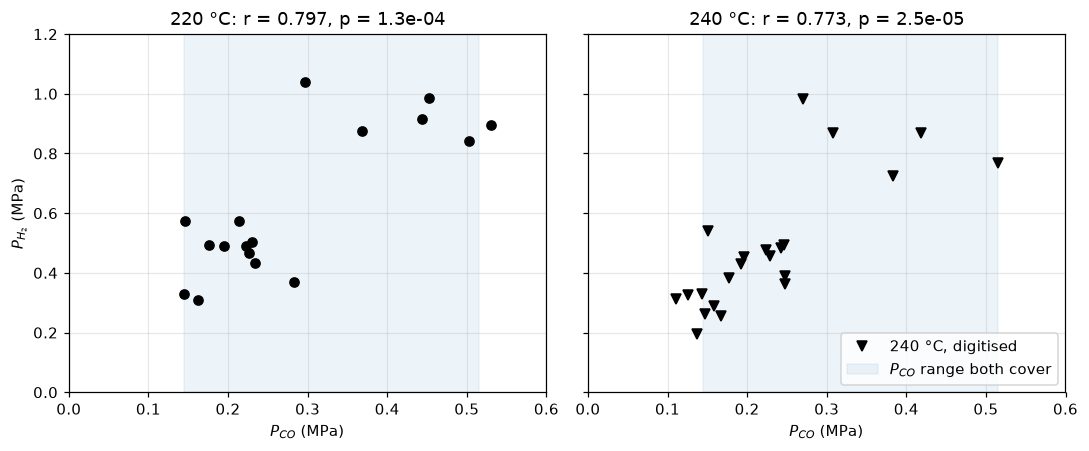

Pearson's r between $P_{\mathrm{CO}}$ and $P_{\mathrm{H_2}}$ is 0.797 at 220 °C (p = 1.3e-04, 17 runs) and 0.773 at 240 °C (p = 2.5e-05, 22 visible runs; 0.731 to 0.802 over the placements of the 23rd run, p = 4.2e-06 to 7.3e-05), each significant at the 1 % level: the partial pressures are correlated. The correlation of their logarithms inflates the variance of a power-law order by a factor 1/(1 - r²) = 2.66 and 2.82. The range of $P_{\mathrm{CO}}$ that both temperatures cover is 0.145 to 0.515 MPa (reading error ±0.003 MPa); the lowest measured $P_{\mathrm{CO}}$ is 0.111 MPa, at 240 °C.

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(10, 4.2), sharey=True)
for a_, T, mk in ((ax[0], 220, "o"), (ax[1], 240, "v")):
    pc, ph = D0["vis"][T]
    a_.plot(pc, ph, mk, color="k", ms=6, label=f"{T} °C, digitised")
    a_.set_xlim(0, 0.6)
    a_.set_ylim(0, 1.2)
    a_.set_xlabel("$P_{CO}$ (MPa)")
    a_.set_title(f"{T} °C: r = {M[f'r1_r_{T}']:.3f}, p = {M[f'r1_p_{T}']:.1e}")
    a_.axvspan(M["r3_common_lo"], M["r3_common_hi"], color="C0", alpha=0.08,
               label="$P_{CO}$ range both cover")
ax[0].set_ylabel("$P_{H_2}$ (MPa)")
ax[1].legend(loc="lower right")
fig.tight_layout()
plt.show()
say("Pearson's r between $P_{\\mathrm{CO}}$ and $P_{\\mathrm{H_2}}$ is <<r220:.3f>> at 220 °C "
    "(p = <<p220:.1e>>, 17 runs) and <<r240:.3f>> at 240 °C (p = <<p240:.1e>>, 22 visible "
    "runs; <<rlo:.3f>> to <<rhi:.3f>> over the placements of the 23rd run, p = <<plo:.1e>> to "
    "<<phi:.1e>>), each significant at the 1 % level: the partial pressures are correlated. The "
    "correlation of their logarithms inflates the variance of a power-law order by a "
    "factor 1/(1 - r²) = <<v220:.2f>> and <<v240:.2f>>. The range of $P_{\\mathrm{CO}}$ "
    "that both temperatures cover is <<lo:.3f>> to <<hi:.3f>> MPa (reading error "
    "±0.003 MPa); the lowest measured $P_{\\mathrm{CO}}$ is <<low:.3f>> MPa, at 240 °C.",
    r220=M["r1_r_220"], p220=M["r1_p_220"], r240=M["r1_r_240"], p240=M["r1_p_240"],
    rlo=M["r1_r_240_lo"], rhi=M["r1_r_240_hi"], plo=M["r1_p_240_lo"], phi=M["r1_p_240_hi"],
    v220=M["r1_vif_log_220"], v240=M["r1_vif_log_240"], lo=M["r3_common_lo"],
    hi=M["r3_common_hi"], low=M["r1_pco_lo_240"])

### R2: Table V and the covariance its design implies

Each $t$ value should be the estimate over its standard error. A printed entry is
compared with the recomputed one within the movement that rounding all three
printed entries can cause (allowance ratio at most 1 when consistent). The ratio of
standard errors $\sigma_a/\sigma_b$ and the correlation of $a$ and $b$ depend only
on the design and the estimates, not on the scatter, so the digitised design
predicts them; at 240 °C the prediction is carried over all 22 placements of the
hidden run.

In [8]:
tbl = pd.DataFrame(
    [(T, prm, printed(PN, f"{prm}_{T}"), printed(PN, f"sd_{prm}_{T}"), printed(PN, f"t_{prm}_{T}"),
      M[f"r2_t_{prm}{T}"], M[f"r2_allow_{prm}{T}"])
     for T in (240, 220) for prm in ("a", "b")],
    columns=["T (°C)", "parameter", "estimate", "sd", "t printed", "t = est/sd", "allowance ratio"])
show(tbl.style.hide(axis="index").format({"t = est/sd": "{:.3f}", "allowance ratio": "{:.2f}"}), "c271")
say("Three of the four $t$ values agree with estimate over standard error within rounding "
    "(allowance ratios <<a1:.2f>>, <<a2:.2f>>, <<a3:.2f>>). For $b$ at 220 °C, 22.26/3.63 = "
    "<<t1:.3f>> against the printed 6.62, <<a4:.1f>> times the rounding allowance; a standard "
    "error of 3.36 (two digits exchanged) gives <<t2:.3f>>, ratio <<a5:.2f>>. The critical "
    "values recompute to <<c1:.4f>> and <<c2:.4f>>, within <<h1:.2f>> and <<h2:.2f>> "
    "half-units of the printed 2.831 and 2.947.",
    a1=M["r2_allow_a240"], a2=M["r2_allow_b240"], a3=M["r2_allow_a220"], t1=M["r2_t_b220"],
    a4=M["r2_allow_b220"], t2=M["r2_t_b220_sd336"], a5=M["r2_allow_b220_sd336"],
    c1=M["r2_tcrit_240"], c2=M["r2_tcrit_220"], h1=M["r2_tcrit_240_half_units"],
    h2=M["r2_tcrit_220_half_units"])
say("From the design, $\\sigma_a/\\sigma_b$ at 240 °C is <<lo:.3f>> to <<hi:.3f>> over the "
    "placements of the hidden run (Monte Carlo of the reading error: ±<<mc:.3f>>), against "
    "<<pr:.3f>> from the printed 9.20/0.97: the route reproduces Table V where it can be "
    "tested (gate G2 passes, below). The correlation of $a$ and $b$ is <<rl:.4f>> to <<rh:.4f>>. "
    "At 220 °C the same route gives <<r220:.3f>> (±<<mc2:.3f>>), correlation <<rho220:.4f>>, "
    "against <<pr220:.3f>> printed (1.38/3.63), a factor <<f:.1f>>. With the printed "
    "$\\sigma_b$ the design implies $\\sigma_a$ = <<sa:.1f>> at 220 °C and $t_a$ = <<ta:.2f>> "
    "(<<sa2:.1f>> and <<ta2:.2f>> with $\\sigma_b$ = 3.36), still above the critical 2.947: "
    "$a$ stays significant, but its printed standard error and $t$ value do not follow from "
    "this design. Which entry is misprinted the page does not decide.",
    lo=M["r2_ratio_240_lo"], hi=M["r2_ratio_240_hi"], mc=M["mc_sd_r2_ratio_240"],
    pr=M["r2_ratio_240_printed"], rl=M["r2_rho_240_lo"], rh=M["r2_rho_240_hi"],
    r220=M["r2_ratio_220"], mc2=M["mc_sd_r2_ratio_220"], rho220=M["r2_rho_220"],
    pr220=M["r2_ratio_220_printed"], f=M["r2_factor_220"], sa=M["r2_sd_a220_design"],
    ta=M["r2_t_a220_design"], sa2=M["r2_sd_a220_design_sd336"], ta2=M["r2_t_a220_design_sd336"])

T (°C),parameter,estimate,sd,t printed,t = est/sd,allowance ratio
240,a,75.76,9.20,8.23,8.235,0.48
240,b,11.61,0.97,12.02,11.969,0.71
220,a,53.11,1.38,38.63,38.486,0.98
220,b,22.26,3.63,6.62,6.132,32.90


Three of the four $t$ values agree with estimate over standard error within rounding (allowance ratios 0.48, 0.71, 0.98). For $b$ at 220 °C, 22.26/3.63 = 6.132 against the printed 6.62, 32.9 times the rounding allowance; a standard error of 3.36 (two digits exchanged) gives 6.625, ratio 0.31. The critical values recompute to 2.8314 and 2.9467, within 0.72 and 0.57 half-units of the printed 2.831 and 2.947.

From the design, $\sigma_a/\sigma_b$ at 240 °C is 9.476 to 9.650 over the placements of the hidden run (Monte Carlo of the reading error: ±0.009), against 9.485 from the printed 9.20/0.97: the route reproduces Table V where it can be tested (gate G2 passes, below). The correlation of $a$ and $b$ is 0.9944 to 0.9956. At 220 °C the same route gives 4.040 (±0.004), correlation 0.9982, against 0.380 printed (1.38/3.63), a factor 10.6. With the printed $\sigma_b$ the design implies $\sigma_a$ = 14.7 at 220 °C and $t_a$ = 3.62 (13.6 and 3.91 with $\sigma_b$ = 3.36), still above the critical 2.947: $a$ stays significant, but its printed standard error and $t$ value do not follow from this design. Which entry is misprinted the page does not decide.

### R3: the apparent activation energy that Table V carries

The covariance at each temperature is scaled to the printed $\sigma_b$ (0.97 and
3.63 1/MPa; scaling to $\sigma_a$ instead would give a smaller $\sigma_E$ at 220 °C,
so $\sigma_b$ is the cautious choice) and propagated into $E_{\mathrm{app}}(P_{\mathrm{CO}})$; the two
temperatures are independent fits. The one-sample statistic of a quoted value is
$z = (E_{\mathrm{app}} - E_{\mathrm{quoted}})/\sigma_E$, minimised over the range
both temperatures cover. Of the 22 placements of the hidden 240 °C run, the one with
the smallest minimum is used.

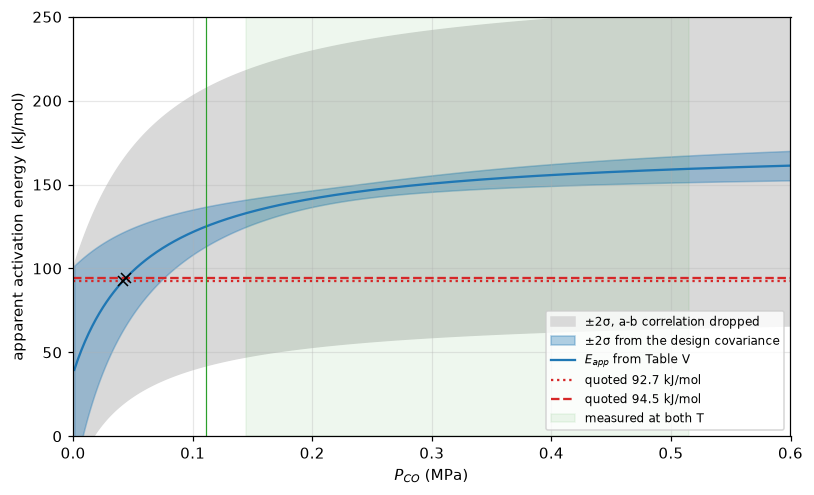

Over the range both temperatures cover, Table V gives $E_{\mathrm{app}}$ = 133.0 to 159.4 kJ/mol (Monte Carlo of the reading error on the lower end: ±0.5), rising with $P_{\mathrm{CO}}$ between the limits 37.4 ($P\to 0$, the activation energy of $a$) and 174.3 kJ/mol ($P\to\infty$, with the adsorption enthalpy of $b$, -68.5 kJ/mol). At Table II's state ($P_{\mathrm{H_2}}$ 0.48, $P_{\mathrm{CO}}$ 0.25 MPa) it is 146.8 kJ/mol. It equals 92.7 kJ/mol at $P_{\mathrm{CO}}$ = 0.0420 MPa and 94.5 at 0.0444 MPa, 2.64 and 2.50 times below the lowest measured $P_{\mathrm{CO}}$ (0.111 MPa). For a pair of runs at Table II's state to give 92.7 or 94.5, the 220 °C run would need 1.67 or 1.64 times the $P_{\mathrm{H_2}}$ of its 240 °C partner, not "nearly the same".

With the design covariance, $z$ for 94.5 kJ/mol is smallest at the lower end of the common range ($P_{\mathrm{CO}}$ = 0.145 MPa), where $\sigma_E$ = 4.03 kJ/mol and $z$ = 9.56 (Monte Carlo of the reading error: ±0.37; over the placements of the hidden run it varies by 0.27); for 92.7 kJ/mol the minimum is 10.00. With $\sigma_b$ = 3.36 at 220 °C the minimum is 10.05. Dropping the a-b correlation (same variances) gives $\sigma_E$ = 42.7 kJ/mol and $z$ = 0.90, which decides nothing: the near-perfect correlation of $a$ and $b$ that the design implies is what makes the band narrow. Table V, at any $P_{\mathrm{CO}}$ both temperatures cover, does not carry 92.7 to 94.5 kJ/mol; it gives that value only at a $P_{\mathrm{CO}}$ below every measured run. Whether Table V or the two rate pairs behind the quoted values (not printed) are at odds with the data, the paper does not let one say.

That $z$ counts only the uncertainty of the fitted curves. The quoted values are ratios of single measured rates, not of fitted ones, so a single run adds its own scatter. At the closest 220/240 °C pair of the digitised design (distance 0.0014 MPa in $(P_{\mathrm{CO}}, P_{\mathrm{H_2}})$) the standard error of the ratio of the two rates, with the scatter of each run taken from the printed $\sigma_b$ and the design, is 12.1 kJ/mol on $E_{\mathrm{app}}$. Added to the curve error, it gives $z$ = 3.00 for 94.5 kJ/mol; with the 240 °C scatter from Table IV's SSE, 2.54. Both stay above 2, so the verdict holds, with the significance of the curve-only 9.56 much reduced. Scaling to the printed $\sigma_b$ rather than $\sigma_a$ is the cautious choice: it gives the larger $\sigma_E$.

The rate maximum in $P_{\mathrm{CO}}$ at fixed $P_{\mathrm{H_2}}$ (a root of the analytic derivative, at $1/b$) lies at 0.0861 MPa at 240 °C and 0.0449 MPa at 220 °C, 0.78 and 0.31 of the lowest $P_{\mathrm{CO}}$ measured at each temperature: every run is on the inhibited side, and the maximum is an extrapolation.

In [9]:
pp = np.linspace(1e-3, 0.6, 600)
E = e_app(pp, PAR0)
sd = sd_e_app(pp, PAR0, C240, C220)
sd0 = sd_e_app(pp, PAR0, C240, C220, rho_zero=True)
fig, ax = plt.subplots(figsize=(7.5, 4.6))
ax.fill_between(pp, E - 2 * sd0, E + 2 * sd0, color="0.85", label="±2σ, a-b correlation dropped")
ax.fill_between(pp, E - 2 * sd, E + 2 * sd, color="C0", alpha=0.35, label="±2σ from the design covariance")
ax.plot(pp, E, "C0", label="$E_{app}$ from Table V")
for item, ls in (("E_app_1", ":"), ("E_app_2", "--")):
    ax.axhline(num(PN, item), color="C3", ls=ls, label=f"quoted {printed(PN, item)} kJ/mol")
ax.axvspan(M["r3_common_lo"], M["r3_common_hi"], color="C2", alpha=0.08, label="measured at both T")
ax.axvline(M["r1_pco_lo_240"], color="C2", lw=0.8)
ax.plot([M["r3_root_927"], M["r3_root_945"]], [num(PN, "E_app_1"), num(PN, "E_app_2")], "kx")
ax.set_xlim(0, 0.6)
ax.set_ylim(0, 250)
ax.set_xlabel("$P_{CO}$ (MPa)")
ax.set_ylabel("apparent activation energy (kJ/mol)")
ax.legend(fontsize=8, loc="lower right")
fig.tight_layout()
plt.show()
say("Over the range both temperatures cover, Table V gives $E_{\\mathrm{app}}$ = <<b0:.1f>> "
    "to <<b1:.1f>> kJ/mol (Monte Carlo of the reading error on the lower end: ±<<mb:.1f>>), "
    "rising with $P_{\\mathrm{CO}}$ between the limits <<l0:.1f>> ($P\\to 0$, the "
    "activation energy of $a$) and <<l1:.1f>> kJ/mol ($P\\to\\infty$, with the adsorption "
    "enthalpy of $b$, <<dh:.1f>> kJ/mol). At Table II's state ($P_{\\mathrm{H_2}}$ 0.48, "
    "$P_{\\mathrm{CO}}$ 0.25 MPa) it is <<es:.1f>> kJ/mol. It equals 92.7 kJ/mol at "
    "$P_{\\mathrm{CO}}$ = <<r1:.4f>> MPa and 94.5 at <<r2:.4f>> MPa, <<f1:.2f>> and <<f2:.2f>> "
    "times below the lowest measured $P_{\\mathrm{CO}}$ (<<low:.3f>> MPa). For a pair of runs "
    "at Table II's state to give 92.7 or 94.5, the 220 °C run would need <<q1:.2f>> or <<q2:.2f>> "
    "times the $P_{\\mathrm{H_2}}$ of its 240 °C partner, not \"nearly the same\".",
    b0=M["r3_band_lo"], b1=M["r3_band_hi"], mb=M["mc_sd_r3_band_lo"], l0=M["r3_E_lim0"],
    l1=M["r3_E_liminf"], dh=M["r3_dHb"], es=M["r3_E_S"], r1=M["r3_root_927"], r2=M["r3_root_945"],
    f1=M["r3_lowest_over_root_927"], f2=M["r3_lowest_over_root_945"], low=M["r1_pco_lo_240"],
    q1=M["r3_ph2_ratio_927"], q2=M["r3_ph2_ratio_945"])
say("With the design covariance, $z$ for 94.5 kJ/mol is smallest at the lower end of the "
    "common range ($P_{\\mathrm{CO}}$ = <<p:.3f>> MPa), where $\\sigma_E$ = <<sd:.2f>> kJ/mol "
    "and $z$ = <<z:.2f>> (Monte Carlo of the reading error: ±<<mz:.2f>>; over the placements of "
    "the hidden run it varies by <<zp:.2f>>); for 92.7 kJ/mol the minimum is <<z2:.2f>>. With "
    "$\\sigma_b$ = 3.36 at 220 °C the minimum is <<z3:.2f>>. Dropping the a-b correlation "
    "(same variances) gives $\\sigma_E$ = <<sd0:.1f>> kJ/mol and $z$ = <<z0:.2f>>, which "
    "decides nothing: the near-perfect correlation of $a$ and $b$ that the design implies is "
    "what makes the band narrow. Table V, at any $P_{\\mathrm{CO}}$ both temperatures cover, "
    "does not carry 92.7 to 94.5 kJ/mol; it gives that value only at a $P_{\\mathrm{CO}}$ "
    "below every measured run. Whether Table V or the two rate pairs behind the quoted values "
    "(not printed) are at odds with the data, the paper does not let one say.",
    p=M["r3_p_at_min"], sd=M["r3_sdE_at_min"], z=M["r3_z_945"], mz=M["mc_sd_r3_z_945"],
    zp=M["r3_z_945_spread_placements"], z2=M["r3_z_927"],
    z3=M["r3_z_945_sd336"], sd0=M["r3_sdE_rho0"], z0=M["r3_z_945_rho0"])
assert min(M["r3_z_945_pair"], M["r3_z_945_pair_tab4"]) > 2
say("That $z$ counts only the uncertainty of the fitted curves. The quoted values are ratios "
    "of single measured rates, not of fitted ones, so a single run adds its own scatter. "
    "At the closest 220/240 °C pair of the digitised design (distance <<dd:.4f>> MPa in "
    "$(P_{\\mathrm{CO}}, P_{\\mathrm{H_2}})$) the standard error of the ratio of the two "
    "rates, with the scatter of each run taken from the printed $\\sigma_b$ and the design, "
    "is <<sp:.1f>> kJ/mol on $E_{\\mathrm{app}}$. Added to the curve error, it gives "
    "$z$ = <<zq:.2f>> for 94.5 kJ/mol; with the 240 °C scatter from Table IV's SSE, "
    "<<zt:.2f>>. Both stay above 2, so the verdict holds, with the significance of the "
    "curve-only <<z:.2f>> much reduced. Scaling to the printed $\\sigma_b$ rather than $\\sigma_a$ is the cautious "
    "choice: it gives the larger $\\sigma_E$.",
    dd=M["r3_pair_dist"], sp=M["r3_sd_pair"], zq=M["r3_z_945_pair"],
    zt=M["r3_z_945_pair_tab4"], z=M["r3_z_945"])
say("The rate maximum in $P_{\\mathrm{CO}}$ at fixed $P_{\\mathrm{H_2}}$ (a root of the "
    "analytic derivative, at $1/b$) lies at <<p240:.4f>> MPa at 240 °C and <<p220:.4f>> MPa "
    "at 220 °C, <<f240:.2f>> and <<f220:.2f>> of the lowest $P_{\\mathrm{CO}}$ measured at each "
    "temperature: every run is on the inhibited side, and the maximum is an extrapolation.",
    p240=M["r3_pmax_240"], p220=M["r3_pmax_220"], f240=M["r3_pmax_240_over_lowest"],
    f220=M["r3_pmax_220_over_lowest"])

### R4: Table V against the paper's other numbers

Figure 8 plots the authors' eq. 16 prediction of every run. Ranked from the top, the
first four triangles and the two highest squares stand alone; the same ranks of eq. 16
with Table V at the digitised design should equal them, without any matching of runs.
The tolerance of each comparison combines the Figure 8 reading error (0.004) with the
design reading error (0.003 MPa) propagated through eq. 16.

In [10]:
F8T = pd.DataFrame(
    [(T, j + 1, f8, f8 - d, d, t)
     for T, sym in ((240, "triangle"), (220, "square"))
     for j, (f8, d, t) in enumerate(zip(
         FIG8[FIG8.symbol == sym].sort_values("R_pred", ascending=False).R_pred.to_numpy(),
         M[f"r4_fig8_dev_{T}"], M[f"r4_fig8_tol_{T}"]))],
    columns=["T (°C)", "rank", "Figure 8", "eq. 16 at design", "difference", "tolerance"])
show(F8T.style.hide(axis="index").format(precision=4), "c272")

T (°C),rank,Figure 8,eq. 16 at design,difference,tolerance
240,1,1.1696,1.1753,-0.0057,0.0086
240,2,0.9664,0.9656,0.0008,0.0074
240,3,0.8122,0.8136,-0.0014,0.0075
240,4,0.8034,0.8037,-0.0003,0.0062
220,1,0.2784,0.2832,-0.0048,0.0046
220,2,0.2410,0.2460,-0.0050,0.0050


Table II repeats one condition at 240 °C four times; Table IV prints the fit
statistics of the five forms without saying at which temperature. With one data set,
every row of Table IV must share one total sum of squares SST = SSE/(1 - R²).

In [11]:
# lo is the largest lower end and hi the smallest upper end of the rows' rounding intervals,
# so every row's interval contains [lo, hi] exactly when the two do not cross
assert M["r4_sst_lo"] <= M["r4_sst_hi"], "the Table IV rounding intervals have no common value"
say("Table II: eq. 16 at the printed partial pressures misses the four measured rates by "
    "<<a:+.3f>>, <<b:+.3f>>, <<c:+.3f>> and <<d:+.3f>> mmol/(min g). Table IV: the rows give SST "
    "<<s4:.4f>>, <<s7:.4f>>, <<s14:.4f>>, <<s15:.4f>> and <<s16:.4f>>, whose rounding intervals "
    "all contain <<lo:.4f>> to <<hi:.4f>>: one data set. "
    "The eq. 16 predictions spread by <<sp240:.3f>> (sum of squares about their mean) over the "
    "240 °C design and by <<sp220:.4f>> over the 220 °C design; only the first is of the size "
    "of that SST, so Table IV is the 240 °C fit. Its SSE ratios to eq. 16 are <<q4:.2f>>, <<q7:.2f>>, <<q14:.2f>> and <<q15:.2f>> "
    "(eqs. 4, 7, 14, 15); eq. 7 is the closest rival.",
    a=M["r4_tab2_res_1"], b=M["r4_tab2_res_2"], c=M["r4_tab2_res_3"], d=M["r4_tab2_res_4"],
    s4=M["r4_sst_eq4"], s7=M["r4_sst_eq7"], s14=M["r4_sst_eq14"], s15=M["r4_sst_eq15"],
    s16=M["r4_sst_eq16"], lo=M["r4_sst_lo"], hi=M["r4_sst_hi"], sp240=M["r4_spread_240"],
    sp220=M["r4_spread_220"], q4=M["r4_sse_ratio_eq4"], q7=M["r4_sse_ratio_eq7"],
    q14=M["r4_sse_ratio_eq14"], q15=M["r4_sse_ratio_eq15"])
say("Table III: the linearised eq. 21 has the highest $R^2$ of eqs. 17 to 21 at <<n:d>> of the "
    "two temperatures; at 220 °C eq. 20 has <<e20:.3f>> against <<e21:.3f>> for eq. 21, at "
    "240 °C eq. 21 has <<f21:.3f>> against <<f20:.3f>> for eq. 20. The paper states: \"The "
    "equation which fits the data best is eq 21\" (p. 172).",
    n=M["r4_tab3_eq21_best_count"], e20=M["r4_tab3_eq20_220"], e21=M["r4_tab3_eq21_220"],
    f21=M["r4_tab3_eq21_240"], f20=M["r4_tab3_eq20_240"])
say("Figure 8 and Table V: <<nin:d>> of the <<n240:d>> top-ranked triangles lie within their "
    "reading tolerance of eq. 16 at the 240 °C design, so $a$ and $b$ at "
    "240 °C are printed as the authors used them. The two top 220 °C squares lie "
    "<<d1:.4f>> and <<d2:.4f>> mmol/(min g) below eq. 16, at up to <<w:.2f>> times their "
    "tolerance: consistent with Table V at 220 °C to about one reading tolerance, which "
    "excludes a gross misprint of $a$ or $b$ there but not a small one. The scatter is "
    "another matter. The printed $\\sigma_b$ at 240 °C with the design implies SSE = "
    "<<s0:.4f>> to <<s1:.4f>> over the 23 runs (over the placements of the hidden run); the "
    "<<ni:d>> triangles of Figure 8 that stand alone already give <<sf:.4f>>, and Table IV "
    "prints 0.062. At 220 °C the printed $\\sigma_b$ implies <<s2:.4f>>.",
    n240=len(M["r4_fig8_dev_240"]), nin=M["r4_fig8_n_in_240"], d1=-M["r4_fig8_dev_220_1"],
    d2=-M["r4_fig8_dev_220_2"], w=M["r4_fig8_dev_220_over_tol"],
    s0=M["r4_sse_implied_240_lo"], s1=M["r4_sse_implied_240_hi"], ni=M["r4_n_iso_triangles"],
    sf=M["r4_sse_fig8_iso"], s2=M["r4_sse_implied_220_lo"])

Table II: eq. 16 at the printed partial pressures misses the four measured rates by -0.081, -0.071, -0.034 and -0.098 mmol/(min g). Table IV: the rows give SST 1.0089, 1.0141, 1.0124, 1.0094 and 1.0000, whose rounding intervals all contain 1.0082 to 1.0119: one data set. The eq. 16 predictions spread by 0.876 (sum of squares about their mean) over the 240 °C design and by 0.0302 over the 220 °C design; only the first is of the size of that SST, so Table IV is the 240 °C fit. Its SSE ratios to eq. 16 are 5.48, 1.16, 3.95 and 3.45 (eqs. 4, 7, 14, 15); eq. 7 is the closest rival.

Table III: the linearised eq. 21 has the highest $R^2$ of eqs. 17 to 21 at 1 of the two temperatures; at 220 °C eq. 20 has 0.970 against 0.968 for eq. 21, at 240 °C eq. 21 has 0.984 against 0.886 for eq. 20. The paper states: "The equation which fits the data best is eq 21" (p. 172).

Figure 8 and Table V: 4 of the 4 top-ranked triangles lie within their reading tolerance of eq. 16 at the 240 °C design, so $a$ and $b$ at 240 °C are printed as the authors used them. The two top 220 °C squares lie 0.0048 and 0.0050 mmol/(min g) below eq. 16, at up to 1.03 times their tolerance: consistent with Table V at 220 °C to about one reading tolerance, which excludes a gross misprint of $a$ or $b$ there but not a small one. The scatter is another matter. The printed $\sigma_b$ at 240 °C with the design implies SSE = 0.0277 to 0.0316 over the 23 runs (over the placements of the hidden run); the 11 triangles of Figure 8 that stand alone already give 0.0323, and Table IV prints 0.062. At 220 °C the printed $\sigma_b$ implies 0.0022.

### R6: the rate law in the paper's CSTR and in an ideal PFR (pymrm)

Table II's condition: 240 °C, 0.79 MPa, H2/CO fed 2, 0.067 L(STP)/(min g). First the
closure: the partial pressures a CSTR must hold if the measured rate is right and the
gas carries H2, CO and water only.

In [12]:
say("Feed <<f:.4f>> mmol/(min g) at 0 °C and 101.325 kPa. Table II row 1 closes at "
    "$P_{\\mathrm{H_2}}$ = <<h:.4f>> and $P_{\\mathrm{CO}}$ = <<c:.4f>> MPa, CO conversion "
    "<<x:.4f>>: <<hu1:.2f>> half-units of the printed 0.25 for CO. Row 3 (H2/CO 1.95, 0.066 "
    "L/(min g)) misses the printed $P_{\\mathrm{H_2}}$ by <<hu3:.2f>> half-units, row 4 by "
    "<<hu4:.2f>>; rows 2 and 4 close within one half-unit in CO (<<c2:.2f>>, <<c4:.2f>>). The "
    "paper computes partial pressures \"from the molar flow rates of all vapor-phase species "
    "present\" (p. 170), hydrocarbon vapour included, so a closure on water alone is a "
    "bound, not a test.",
    f=M["r6_feed"], h=M["r6_cl1_PH2"], c=M["r6_cl1_PCO"], x=M["r6_cl1_X"],
    hu1=M["r6_cl1_PCO_hu"], hu3=M["r6_cl3_PH2_hu"], hu4=M["r6_cl4_PH2_hu"],
    c2=M["r6_cl2_PCO_hu"], c4=M["r6_cl4_PCO_hu"])

Feed 2.9892 mmol/(min g) at 0 °C and 101.325 kPa. Table II row 1 closes at $P_{\mathrm{H_2}}$ = 0.4798 and $P_{\mathrm{CO}}$ = 0.2399 MPa, CO conversion 0.2268: 2.02 half-units of the printed 0.25 for CO. Row 3 (H2/CO 1.95, 0.066 L/(min g)) misses the printed $P_{\mathrm{H_2}}$ by 6.12 half-units, row 4 by 1.69; rows 2 and 4 close within one half-unit in CO (0.04, 0.16). The paper computes partial pressures "from the molar flow rates of all vapor-phase species present" (p. 170), hydrocarbon vapour included, so a closure on water alone is a bound, not a test.

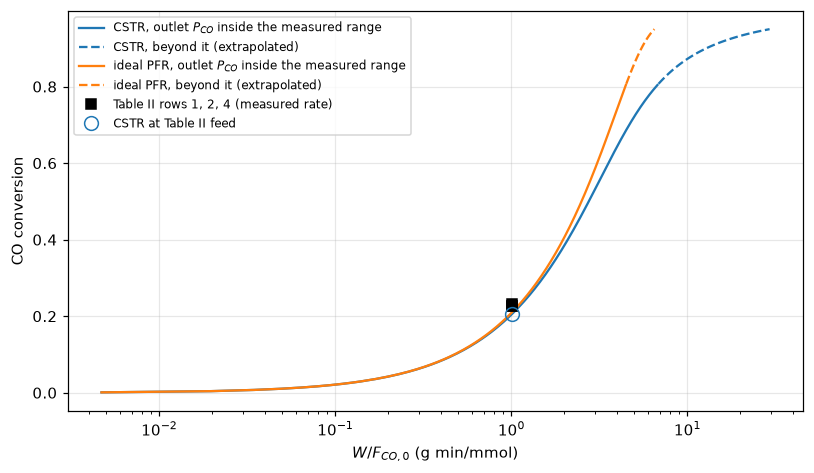

At the Table II feed the CSTR (pymrm `newton` on the three species balances) reaches CO conversion 0.2048 with rate 0.6121 mmol/(min g) at $P_{\mathrm{CO}}$ 0.2425 MPa, 0.072 mmol/(min g) below the mean measured rate of the three repeats at H2/CO 2 (rows 1, 2, 4). An ideal PFR of the same catalyst mass converts 0.2093 (pymrm, extrapolated on the grid ladder); at conversion 0.5 the CSTR needs 1.100 times the PFR's catalyst. Over the paper's space velocities the CSTR converts 0.163 at 0.085 and 0.847 at 0.008 L(STP)/(min g); beyond CO conversion 0.804 (space velocity below 0.0099 in the CSTR, 0.0150 in the PFR) the outlet $P_{\mathrm{CO}}$ falls under the lowest measured at 240 °C and the rate law is extrapolated (dashed). At 220 °C, Table V gives conversion 0.0521 at the same feed, against 0.0856 if the 240 °C rate is moved by 94.5 kJ/mol: a rate 1.645 times higher, the reactor-scale size of the gap in R3. The PFR is ideal and isothermal: no pore diffusion, heat removal or fixed-bed performance is implied.

In [13]:
P_T2, Q_T2 = num(PN, "tab2_P"), num(PN, "tab2_q")
xx = np.linspace(1e-3, 0.95, 300)
wf_c = cstr_wf(xx, PAR0["a240"], PAR0["b240"], P_T2)
wf_p = pfr_wf(xx, PAR0["a240"], PAR0["b240"], P_T2)
inside = xx <= M["r6_x_boundary"]
fig, ax = plt.subplots(figsize=(7.5, 4.4))
for wf, lab, col in ((wf_c, "CSTR", "C0"), (wf_p, "ideal PFR", "C1")):
    ax.plot(wf[inside], xx[inside], col, label=f"{lab}, outlet $P_{{CO}}$ inside the measured range")
    ax.plot(wf[~inside], xx[~inside], col, ls="--", label=f"{lab}, beyond it (extrapolated)")
tau0 = (1 + num(PN, "tab2_m")) / M["r6_feed"]
x_meas = [closure(tab2(PN, k)["R"], Q_T2, 2.0, P_T2)[2] for k in (1, 2, 4)]
ax.plot([tau0] * 3, x_meas, "ks", label="Table II rows 1, 2, 4 (measured rate)")
ax.plot([tau0], [M["r6_cstr_X"]], "C0o", mfc="none", ms=9, label="CSTR at Table II feed")
ax.set_xscale("log")
ax.set_xlabel("$W/F_{CO,0}$ (g min/mmol)")
ax.set_ylabel("CO conversion")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()
say("At the Table II feed the CSTR (pymrm `newton` on the three species balances) reaches "
    "CO conversion <<x:.4f>> with rate <<r:.4f>> mmol/(min g) at $P_{\\mathrm{CO}}$ <<pc:.4f>> "
    "MPa, <<d:.3f>> mmol/(min g) below the mean measured rate of the three repeats at H2/CO 2 "
    "(rows 1, 2, 4). An ideal "
    "PFR of the same catalyst mass converts <<xp:.4f>> (pymrm, extrapolated on the grid "
    "ladder); at conversion 0.5 the CSTR needs <<wr:.3f>> times the PFR's catalyst. Over the "
    "paper's space velocities the CSTR converts <<x1:.3f>> at 0.085 and <<x2:.3f>> at 0.008 "
    "L(STP)/(min g); beyond CO conversion <<xb:.3f>> (space velocity below <<svc:.4f>> in the "
    "CSTR, <<svp:.4f>> in the PFR) the outlet $P_{\\mathrm{CO}}$ falls under the lowest "
    "measured at 240 °C and the rate law is extrapolated (dashed). At 220 °C, Table V gives "
    "conversion <<x220:.4f>> at the same feed, against <<x220b:.4f>> if the 240 °C rate is "
    "moved by 94.5 kJ/mol: a rate <<rr:.3f>> times higher, the reactor-scale size of the gap in "
    "R3. The PFR is ideal and isothermal: no pore diffusion, heat removal or fixed-bed "
    "performance is implied.",
    x=M["r6_cstr_X"], r=M["r6_cstr_rate"], pc=M["r6_cstr_PCO"], d=-M["r6_cstr_rate_minus_meas"],
    xp=M["r6_pfr_X"], wr=M["r6_wf_ratio_05"], x1=M["r6_X_sv_hi"], x2=M["r6_X_sv_lo"],
    xb=M["r6_x_boundary"], svc=M["r6_sv_boundary_cstr"], svp=M["r6_sv_boundary_pfr"],
    x220=M["r6_cstr220_X"], x220b=M["r6_cstr220_from240_X"], rr=M["r6_cstr220_ratio"])

## Validation

- **V1, check values:** every row of `check_values.csv`, above.
- **V2, closed forms:** the limits of $E_{\mathrm{app}}$ against the function at
  $P_{\mathrm{CO}} = 10^9$ MPa; the roots of $E_{\mathrm{app}}$ by `find_roots` against
  the closed form; the rate maximum by `find_roots` on the analytic derivative against
  $1/b$; the conversion at the measured-range boundary by `find_roots` against its
  closed form.
- **V3, covariance:** the analytic sensitivities against central differences; the
  Monte Carlo of the reading error (12 seeds of 200 draws, own generator per seed);
  gate G2, the printed 240 °C ratio inside the design band widened by three Monte
  Carlo standard deviations.
- **V4, reactors:** the CSTR `newton` solution against its closed form
  $W/F_{\mathrm{CO,0}}(X)$; the PFR on 50 to 800 cells: observed order of the outlet
  conversion (first-order upwind), Richardson extrapolation against the closed form,
  and a round-off companion factorised with a second column ordering.

In [14]:
G2_LO = M["r2_ratio_240_lo"] - 3 * M["mc_sd_r2_ratio_240"]
G2_HI = M["r2_ratio_240_hi"] + 3 * M["mc_sd_r2_ratio_240"]
say("V2: the $P\\to\\infty$ limit and the function at $10^9$ MPa differ by less than 1e-6 "
    "kJ/mol (here <<g1:.1e>>, a remainder of order $1/(bP)$); the roots by `find_roots` and in "
    "closed form by a relative 1e-10 at most (here <<g2:.0e>>); the rate maxima and $1/b$ by "
    "less than 1e-10 (here <<g3:.0e>>); the boundary conversion and its closed form by less "
    "than 1e-10 (here <<g4:.0e>>). V3: analytic and central-difference sensitivities agree to "
    "1e-8 relative (here <<g5:.1e>>; truncation and round-off of steps 1e-6); the Monte Carlo "
    "spreads move by at most <<ms:.0f>> % between seeds. Gate G2: the printed ratio <<pr:.3f>> "
    "lies inside <<lo:.3f>> to <<hi:.3f>>, the design band widened by three Monte Carlo "
    "standard deviations. V4: the CSTR solution meets its closed form to 1e-11 relative (here "
    "<<g6:.0e>>); the PFR orders are <<o1:.3f>> to <<o2:.3f>> (theory 1) on a finest difference "
    "of <<fd:.1e>>, the companion moves the outlet by less than 1e-13 (here <<pg:.0e>>), and "
    "the Richardson value meets the closed form to 1e-8 (here <<rg:.1e>>; the finest grid "
    "alone: <<fe:.1e>>).",
    g1=M["v2_liminf_gap"], g2=M["v2_root_gap"], g3=max(M["v2_pmax_gap_240"], M["v2_pmax_gap_220"]),
    g4=M["v2_boundary_gap"], g5=M["v3_jac_gap"],
    ms=100 * M["v3_mc_seed_spread_max"],
    pr=M["r2_ratio_240_printed"], lo=G2_LO, hi=G2_HI, g6=M["v4_cstr_closed_gap"],
    o1=M["v4_order_min"], o2=M["v4_order_max"], fd=M["v4_finest_diff"], pg=M["v4_permc_gap"],
    rg=M["v4_rich_gap"], fe=M["v4_pfr_err_finest"])

V2: the $P\to\infty$ limit and the function at $10^9$ MPa differ by less than 1e-6 kJ/mol (here 8.7e-09, a remainder of order $1/(bP)$); the roots by `find_roots` and in closed form by a relative 1e-10 at most (here 7e-16); the rate maxima and $1/b$ by less than 1e-10 (here 1e-14); the boundary conversion and its closed form by less than 1e-10 (here 0e+00). V3: analytic and central-difference sensitivities agree to 1e-8 relative (here 9.4e-11; truncation and round-off of steps 1e-6); the Monte Carlo spreads move by at most 7 % between seeds. Gate G2: the printed ratio 9.485 lies inside 9.451 to 9.675, the design band widened by three Monte Carlo standard deviations. V4: the CSTR solution meets its closed form to 1e-11 relative (here 0e+00); the PFR orders are 1.000 to 1.001 (theory 1) on a finest difference of 5.5e-06, the companion moves the outlet by less than 1e-13 (here 6e-16), and the Richardson value meets the closed form to 1e-8 (here 9.6e-10; the finest grid alone: 5.5e-06).

### The claims

Every number above is registered with how it is checked. Arithmetic on printed numbers
and closed forms are held to a relative 1e-6. A number that rests on the digitised
design carries three times its Monte Carlo spread under the reading error (for a p value,
that of ln p); one that rests on a single reading carries three reading errors.

In [15]:
TIGHT = 1e-6
VIA_MC = {"r2_ratio_240_lo": "r2_ratio_240", "r2_ratio_240_hi": "r2_ratio_240",
          "r2_rho_240_lo": "r2_rho_240", "r2_rho_240_hi": "r2_rho_240",
          "r2_sd_a220_design": "r2_ratio_220", "r2_sd_a220_design_sd336": "r2_ratio_220",
          "r2_t_a220_design": "r2_ratio_220", "r2_t_a220_design_sd336": "r2_ratio_220",
          "r2_factor_220": "r2_ratio_220", "r1_r_240_lo": "r1_r_240",
          "r1_r_240_hi": "r1_r_240", "r3_sd_pair": "r3_z_945",
          "r3_z_945_pair": "r3_z_945", "r3_z_945_pair_tab4": "r3_z_945",
          "r3_z_945_sd336": "r3_z_945", "r4_sse_implied_240_lo": "r4_sse_implied_240",
          "r4_sse_implied_240_hi": "r4_sse_implied_240"}
READ = {"r1_pco_lo_220", "r1_pco_hi_220", "r1_pco_lo_240", "r1_pco_hi_240", "r3_common_lo",
        "r3_common_hi", "r3_p_at_min", "r3_lowest_over_root_927", "r3_lowest_over_root_945",
        "r3_pmax_240_over_lowest", "r3_pmax_220_over_lowest"}
OTHER_RTOL = {"r4_spread_220": (0.05, "three times the 240 C Monte Carlo spread, rounded up"),
              "r4_sse_implied_220_lo": (0.08, "three times the 240 C Monte Carlo spread"),
              "r4_sse_implied_220_hi": (0.08, "three times the 240 C Monte Carlo spread"),
              "r4_sse_fig8_iso": (0.2, "Figure 8 reading error 0.004 on 11 residuals"),
              "r3_z_945_spread_placements": (0.15, "z itself carries 4 %; the spread a difference")}
FIG8_READ = ("r4_fig8_dev_220_1", "r4_fig8_dev_220_2", "r4_fig8_dev_220_over_tol")
BOUNDS = {
    "v2_liminf_gap": (None, 1e-6, "theory", "remainder of order 1/(b P) at P = 1e9 MPa", False),
    "v2_root_gap": (None, 1e-10, "tolerance", "find_roots xtol 1e-14 on a root near 0.04", False),
    "v2_pmax_gap_240": (None, 1e-10, "tolerance", "root of 1 - b P by find_roots: an identity up to xtol", True),
    "v2_pmax_gap_220": (None, 1e-10, "tolerance", "root of 1 - b P by find_roots: an identity up to xtol", True),
    "v2_boundary_gap": (None, 1e-10, "tolerance", "find_roots against u = P_min/(P - 2 P_min): an identity up to xtol", True),
    "v3_jac_gap": (None, 1e-8, "theory", "central differences, step 1e-6 relative: truncation 1e-12, round-off 1e-10"),
    "v4_cstr_closed_gap": (None, 1e-11, "tolerance", "newton tol 1e-13 on flows of order 1"),
    "v4_order_min": (0.9, 1.1, "theory", "first-order upwind"),
    "v4_order_max": (0.9, 1.1, "theory", "first-order upwind"),
    "v4_finest_diff": (1e-10, None, "theory", "at least 1e3 times the round-off of a conversion"),
    "v4_permc_gap": (None, 1e-13, "chosen", "round-off of a 2400-unknown sparse solve"),
    "v4_rich_gap": (None, 1e-8, "chosen", "second-order remainder after one Richardson step on 400 and 800 cells"),
    "v3_mc_seed_spread_max": (None, 0.1, "chosen", "12 seeds of 200 draws: the seed moves each spread little"),
    "x_bpre_hu": (-1e-9, 1e-9, "identity", "F2.3 b_pre is b(220 C) in 1/bar: 22.26/10"),
    "x_Tkin_gap": (-1e-9, 1e-9, "identity", "F2.3's reference temperature is 220 C in kelvin"),
}
EXACT = {"r1_n_220": None, "r1_n_240": None,
         "r4_n_iso_triangles": "structural: isolated triangles in the Figure 8 CSV"}
SKIP = {"r3_dz_lo_rel", "r2_g2_margin", "r2_g2_margin_rel", "r3_p_at_min_over_lo",
        "r4_fig8_n_in_240"}


def tol_of(name, M):
    """CI tolerance of a value claim, from its basis."""
    if name in ("r1_p_220", "r1_p_240", "r1_p_240_lo", "r1_p_240_hi"):
        return float(np.expm1(3 * M[f"mc_sd_{name[:8]}"])), "three Monte Carlo spreads of ln p"
    key = VIA_MC.get(name, name)
    if f"mc_sd_{key}" in M:
        return max(3 * M[f"mc_sd_{key}"] / abs(M[key] if key in M else M[key + "_lo"]), TIGHT), \
            "three Monte Carlo spreads of the design reading error"
    if name in READ:
        return 3 * DESIGN_ERR / M["r1_pco_lo_240"], "three reading errors on the lowest P_CO"
    if name in OTHER_RTOL:
        return OTHER_RTOL[name]
    if name in FIG8_READ:            # one reading tolerance of the worse square
        return float(np.max(M["r4_fig8_tol_220"] / np.abs(M["r4_fig8_dev_220"]))), \
            "one reading tolerance (Figure 8 and design)"
    if name.startswith("mc_sd_"):
        return 3 * M[name + "_seed_spread"] / M[name], "three times the spread over 12 seeds"
    return TIGHT, None


def register(M):
    for name, v in M.items():
        if name.startswith("_") or name in SKIP or name.endswith("_seed_spread") \
                or isinstance(v, np.ndarray):
            continue
        if name.startswith("mc_sd_") and name not in ("mc_sd_r2_ratio_240", "mc_sd_r2_ratio_220",
                                                       "mc_sd_r3_band_lo", "mc_sd_r3_z_945"):
            continue
        if name in BOUNDS:
            lo, hi, basis, note, *st = BOUNDS[name]
            claims.bound(name, abs(v) if lo is not None and lo < 0 else v, min=lo, max=hi,
                         basis=basis, note=note, structural=bool(st and st[0]))
        elif name in EXACT:
            note = EXACT[name]
            claims.exact(name, v, structural=bool(note), note=note)
        elif isinstance(v, (bool, np.bool_)):
            continue                     # verdicts, registered with their margins below
        else:
            rt, note = tol_of(name, M)
            claims.value(name, v, rtol=rt, note=note)
    claims.exact("r3_min_at_lower_end", M["r3_min_at_lower_end"], margin=M["r3_dz_lo_rel"],
                 min_margin=0.1, note="margin: slope of z at the lower end times the range, over z")
    claims.exact("r3_z_above_2", M["r3_z_above_2"], margin=(M["r3_z_945"] - 2) / M["mc_sd_r3_z_945"],
                 min_margin=3.0, note="margin in Monte Carlo standard deviations of z")
    claims.exact("r2_g2_pass", M["r2_g2_pass"], margin=M["r2_g2_margin_rel"], min_margin=1e-3,
                 note="printed 240 C ratio inside the design band widened by 3 Monte Carlo sd")
    claims.count("r4_fig8_n_in_240", M["r4_fig8_tol_240"] - np.abs(M["r4_fig8_dev_240"]), 0.0,
                 min_margin=1e-3, note="top 240 C triangles of Figure 8 within tolerance of eq. 16")


register(M)
print(f"{len(claims.metrics)} claims registered")

162 claims registered


### The break table

Every non-structural claim has a row that fails it. Each row injects one defect
through `Cfg` (a reading of the paper, a printed entry mistyped, a unit, a statistic,
a solver or grid setting) and reruns the parts of the study the defect reaches. Only
finite values are recorded; a row under which a study raises is listed as a crash.
The row that reads ln as log10 leaves no root of $E_{\mathrm{app}}$ = 92.7 or 94.5: both
closed-form limits then lie below them and $E_{\mathrm{app}}$ is monotonic between its
limits, so the roots record nan as a shown non-existence (checklist rule 11). The
control fails nothing.

In [16]:
def printed_row(item, new, parts=ALL):
    """A break row that mistypes one printed entry."""
    pn = PN.copy()
    i = pn.index[pn["item"] == item][0]
    old = pn.at[i, "printed"]
    pn.at[i, "printed"] = new
    return f"printed {item} {old} -> {new}", replace(C0, pn=pn), parts


NO_MC = ("design", "eapp", "r4", "reactor", "cross")
DEFECTS = [
    ("ln read as log10 in E_app", replace(C0, log=np.log10), ("design", "eapp", "cross")),
    ("temperatures in Celsius, not kelvin", replace(C0, t_off=0.0), NO_MC),
    ("b(220 C) and b(240 C) exchanged", replace(C0, swap_b=True), NO_MC),
    ("pressures in bar entering eq. 16 (x10)", replace(C0, p_scale=10.0), NO_MC),
    ("critical t one-sided at 99 % (0.99 quantile)", replace(C0, tcrit_q=0.99), ("design",)),
    ("a-b covariance dropped in sd_E (rho = 0)", replace(C0, rho_zero=True), ("design", "eapp", "mc")),
    ("hidden 23rd run at 240 C dropped (22 runs)", replace(C0, hidden="drop"), ("design", "eapp", "r4")),
    ("Table IV SST from R^2, not 1 - R^2", replace(C0, sst_r2=True), ("design", "r4")),
    ("eq. 16 read as a CO rate in the reactors (x3)", replace(C0, rate_is_co=True), ("design", "reactor")),
    ("standard state 25 C for the feed", replace(C0, t_std=298.15), ("design", "reactor")),
    ("usage ratio U = 3", replace(C0, u_ratio=3.0), ("design", "reactor")),
    ("Figures 1 and 2 exchanged", replace(C0, swap_figs=True), ("design", "eapp", "mc", "r4")),
    ("b-sensitivity without its factor 2", replace(C0, b_col=0.5), ("design", "eapp", "mc", "r4")),
    ("P -> inf limit with dH_b once, not twice", replace(C0, lim_k=1.0), ("design", "eapp")),
    ("design reading error 0.03 MPa in the Monte Carlo", replace(C0, read_err=0.03), ("design", "eapp", "mc")),
    ("Monte Carlo with 10 draws per seed", replace(C0, n_draws=10), ("design", "eapp", "mc")),
    ("variance inflation 1/(1 - r), not 1/(1 - r^2)", replace(C0, vif_power=1.0), ("design",)),
    ("Figure 8 pairs read as two markers at their centroid", replace(C0, fig8_pairs=True), ("design", "eapp", "r4")),
    ("PFR tau off by n^-1/2 (grid-dependent)", replace(C0, tau_defect=1.0), ("design", "reactor")),
    ("PFR companion at tau 1e-9 high", replace(C0, comp_tau=1 + 1e-9), ("design", "reactor")),
    ("PFR feed 1e9 times (conversion near 1e-10)", replace(C0, feed_scale=1e9), ("design", "reactor")),
    printed_row("a_240", "75.67", NO_MC),
    printed_row("a_220", "53.71", NO_MC),
    printed_row("b_220", "22.62", NO_MC),
    printed_row("b_240", "11.16", NO_MC),
    printed_row("sd_a_240", "9.02", ("design",)),
    printed_row("sd_b_240", "0.79", ("design", "eapp", "r4")),
    printed_row("sd_a_220", "1.83", ("design",)),
    printed_row("sd_b_220", "3.36", ("design", "eapp", "r4")),
    printed_row("t_a_240", "8.32", ("design",)),
    printed_row("t_b_240", "12.20", ("design",)),
    printed_row("t_a_220", "38.36", ("design",)),
    printed_row("t_b_220", "6.26", ("design",)),
    printed_row("tcrit_240", "2.381", ("design",)),
    printed_row("tcrit_220", "2.497", ("design",)),
    printed_row("E_app_1", "97.2", ("design", "eapp")),
    printed_row("E_app_2", "95.4", ("design", "eapp", "reactor")),
    printed_row("tab2_row1_R", "0.687", ("design", "eapp", "r4", "reactor")),
    printed_row("tab2_row2_R", "0.608", ("design", "r4", "reactor")),
    printed_row("tab2_row3_R", "0.549", ("design", "r4", "reactor")),
    printed_row("tab2_row4_R", "0.649", ("design", "r4", "reactor")),
    printed_row("tab2_row1_PH2", "0.84", ("design", "eapp", "r4", "reactor")),
    printed_row("tab2_row2_PH2", "0.84", ("design", "r4", "reactor")),
    printed_row("tab2_row3_PH2", "0.54", ("design", "r4", "reactor")),
    printed_row("tab2_row4_PH2", "0.74", ("design", "r4", "reactor")),
    printed_row("tab2_row1_PCO", "0.52", ("design", "eapp", "r4", "reactor")),
    printed_row("tab2_row2_PCO", "0.42", ("design", "r4", "reactor")),
    printed_row("tab2_row3_PCO", "0.52", ("design", "r4", "reactor")),
    printed_row("tab2_row4_PCO", "0.42", ("design", "r4", "reactor")),
    printed_row("tab2_q", "0.076", ("design", "reactor")),
    printed_row("tab2_P", "0.97", ("design", "reactor")),
    printed_row("range_SV_hi", "0.058", ("design", "reactor")),
    printed_row("range_SV_lo", "0.080", ("design", "reactor")),
    printed_row("tab4_eq16_SSE", "0.026", ("design", "r4")),
    printed_row("tab4_eq4_SSE", "0.430", ("design", "r4")),
    printed_row("tab4_eq7_SSE", "0.027", ("design", "r4")),
    printed_row("tab4_eq14_SSE", "0.254", ("design", "r4")),
    printed_row("tab4_eq15_SSE", "0.241", ("design", "r4")),
    printed_row("tab4_eq16_R2", "0.983", ("design", "r4")),
    printed_row("tab3_eq20_220", "0.960", ("design", "r4")),
    printed_row("tab3_eq21_240", "0.884", ("design", "r4")),
    printed_row("tab3_eq21_220", "0.986", ("design", "r4")),
    printed_row("tab3_eq20_240", "0.868", ("design", "r4")),
]
CONTROLS = [("control: clean rerun without the Monte Carlo", C0, NO_MC)]
claims.define_rows([r_ for r_, _, _ in CONTROLS + DEFECTS])
BREAK, CRASH = [], set()
NOROOT_CLAIMS = {"r3_root_927", "r3_root_945", "r3_lowest_over_root_927",
                 "r3_lowest_over_root_945", "v2_root_gap"}
for row, c_, parts in CONTROLS + DEFECTS:
    try:
        with np.errstate(divide="ignore", invalid="ignore"):
            Mb = study(c_, parts)
    except (ValueError, RuntimeError, np.linalg.LinAlgError) as e:
        print(f"{row}: {type(e).__name__}: {e}")
        Mb = {}
    noroot = bool(Mb.get("_noroot", False))
    rec = 0
    for name in claims.metrics:
        if claims.metrics[name].get("structural"):
            continue
        x_ = Mb.get(name, None)
        if name in ("x_bpre_hu", "x_Tkin_gap") and x_ is not None:
            x_ = abs(x_)
        if name == "r3_min_at_lower_end" and x_ is None:
            continue
        if x_ is None:
            continue
        if isinstance(x_, (float, np.floating)) and not np.isfinite(x_) and not noroot:
            continue                      # only finite values, except a shown non-existence
        if name == "r4_fig8_n_in_240" and "r4_fig8_tol_240" in Mb:
            x_ = int(np.sum(Mb["r4_fig8_tol_240"] - np.abs(Mb["r4_fig8_dev_240"]) > 0))
        # the closed-form bound test of E_app (e_app_limits) shows that no root exists:
        # that failure is the detection for the claims that need the root
        by_failure = noroot and name in NOROOT_CLAIMS and not np.isfinite(x_)
        BREAK.append((row, name, claims.breaks(row, name, x_, detects_by_failure=by_failure)))
        rec += 1
    if rec == 0:
        CRASH.add(row)

In [17]:
# The break table: one line per row, with the number of claims it fails.
by_row = {}
for r_, m_, c_ in BREAK:
    by_row.setdefault(r_, []).append(c_)
_bad = [r_ for r_ in by_row if r_.startswith("control") and any(by_row[r_])]
assert not _bad, f"a control row failed a claim: {_bad}"
print(f"{'injected defect':<56} {'claims failed':>13}")
for r_, cs in by_row.items():
    print(f"{r_[:56]:<56} {sum(cs):13d}")
_caught = {m_ for r_, m_, c_ in BREAK if c_ and r_ not in CRASH}
print(f"rows that only crash: {', '.join(sorted(CRASH)) or 'none'}")
_open = sorted(k_ for k_ in claims.metrics if k_ not in _caught
               and not claims.metrics[k_].get("structural"))
print(f"\n{len(by_row)} rows; {len(_caught)} of {len(claims.metrics)} claims are failed by at "
      f"least one row; open: {', '.join(_open) or 'none'}")

injected defect                                          claims failed
control: clean rerun without the Monte Carlo                         0
ln read as log10 in E_app                                           27
temperatures in Celsius, not kelvin                                 35
b(220 C) and b(240 C) exchanged                                     74
pressures in bar entering eq. 16 (x10)                              71
critical t one-sided at 99 % (0.99 quantile)                         4
a-b covariance dropped in sd_E (rho = 0)                             9
hidden 23rd run at 240 C dropped (22 runs)                          12
Table IV SST from R^2, not 1 - R^2                                   7
eq. 16 read as a CO rate in the reactors (x3)                       12
standard state 25 C for the feed                                    27
usage ratio U = 3                                                   25
Figures 1 and 2 exchanged                                           33
b-sens

## What pymrm adds

The rate law, its apparent activation energy, the design covariance and the Table
audits (R1 to R4) are closed forms and scipy statistics: pymrm contributes nothing
there beyond `pymrm.checks.find_roots`, which locates every root the page quotes (the
activation-energy roots, the rate maxima, the edge of the measured range) and refuses
a bracket without exactly one root. The reactors are where pymrm does the work: the
slurry CSTR as three species balances solved by `newton` with a `NumJac` Jacobian,
and the ideal plug-flow reactor as steady upwind convection of the molar flows
(`construct_convflux_upwind`, `construct_div`, an `{"outflow": True}` outlet read by
`compute_boundary_values`), checked by `pymrm.checks.observed_orders` on a grid
ladder and against their closed forms. The same PFR is the starting point for the
non-ideal reactors that reuse these kinetics (`F2.3`'s slurry bubble column).

## Reuse

In [18]:
say("- **Rate basis.** Eq. 16 gives H2 plus CO consumed per gram of *unreduced* catalyst; CO "
    "is consumed at $-R/(1+U)$ with $U$ near 2. The catalyst lost <<loss>> wt % on reduction "
    "(p. 170), so a rate per gram of reduced catalyst is larger.\n"
    "- **Range.** The fits hold at 220 and 240 °C over the partial pressures of Figures 1 and "
    "2 ($P_{\\mathrm{CO}}$ <<lo:.3f>> to <<hi:.3f>> MPa at both). Every run lies above "
    "$P_{\\mathrm{CO}} = 1/b$, so the rate maximum is an extrapolation, and so is any "
    "conversion that takes the outlet $P_{\\mathrm{CO}}$ below the lowest measured value "
    "(dashed lines in R6).\n"
    "- **Temperature dependence.** A two-point Arrhenius form through Table V (as `F2.3` uses, "
    "below) carries $E_{\\mathrm{app}}$ = <<b0:.0f>> to <<b1:.0f>> kJ/mol over the measured "
    "range, not the <<q1>> to <<q2>> kJ/mol of the abstract. A model that needs the quoted "
    "value must change the temperature dependence of $a$ or $b$, and Table V alone does not "
    "say which.\n"
    "- **Parameter uncertainty.** The design correlates $a$ and $b$ to <<r240:.3f>> (240 °C) "
    "and <<r220:.3f>> (220 °C). Propagate them jointly: dropping the correlation multiplies the "
    "standard error of $E_{\\mathrm{app}}$ by <<f:.1f>>.\n"
    "- Related pages: `F2.3` (slurry bubble column with these kinetics), `C1.1` "
    "(Hougen-Watson discrimination), `C2.13` (a self-inhibited rate with a maximum in an "
    "integral reactor), `C2.1` (an LHHW parameter set and its reactor).",
    loss=printed(PN, "reduction_loss"), lo=M["r3_common_lo"], hi=M["r3_common_hi"],
    b0=M["r3_band_lo"], b1=M["r3_band_hi"], q1=printed(PN, "E_abstract_lo"),
    q2=printed(PN, "E_abstract_hi"), r240=M["r2_rho_240_lo"], r220=M["r2_rho_220"],
    f=M["r3_sdE_rho0"] / M["r3_sdE_at_min"])

- **Rate basis.** Eq. 16 gives H2 plus CO consumed per gram of *unreduced* catalyst; CO is consumed at $-R/(1+U)$ with $U$ near 2. The catalyst lost 18 wt % on reduction (p. 170), so a rate per gram of reduced catalyst is larger.
- **Range.** The fits hold at 220 and 240 °C over the partial pressures of Figures 1 and 2 ($P_{\mathrm{CO}}$ 0.145 to 0.515 MPa at both). Every run lies above $P_{\mathrm{CO}} = 1/b$, so the rate maximum is an extrapolation, and so is any conversion that takes the outlet $P_{\mathrm{CO}}$ below the lowest measured value (dashed lines in R6).
- **Temperature dependence.** A two-point Arrhenius form through Table V (as `F2.3` uses, below) carries $E_{\mathrm{app}}$ = 133 to 159 kJ/mol over the measured range, not the 93 to 95 kJ/mol of the abstract. A model that needs the quoted value must change the temperature dependence of $a$ or $b$, and Table V alone does not say which.
- **Parameter uncertainty.** The design correlates $a$ and $b$ to 0.994 (240 °C) and 0.998 (220 °C). Propagate them jointly: dropping the correlation multiplies the standard error of $E_{\mathrm{app}}$ by 10.6.
- Related pages: `F2.3` (slurry bubble column with these kinetics), `C1.1` (Hougen-Watson discrimination), `C2.13` (a self-inhibited rate with a maximum in an integral reactor), `C2.1` (an LHHW parameter set and its reactor).

In [19]:

say("`F2.3`'s constants (imported from its `model.py`): activation temperature of $a$ "
    "<<ta>> K against <<ta0:.2f>> K from Table V here (difference <<dta:.1e>> K); of $b$ <<tb>> "
    "K against <<tb0:.2f>> K (difference <<dtb:.3f>> K, the printed rounding); prefactor "
    "<<ap>> mol/(s kg bar²) against Table V's 53.11/6000, <<hu:.2f>> half-units of the last "
    "printed digit of 53.11; $b$ prefactor equal to 22.26/10. Its rate in SI is therefore "
    "Table V's, and carries the apparent activation energy of R3, not 92.7 to 94.5 kJ/mol.",
    ta=F23P["a_act"], ta0=M["r3_Ta"], dta=M["x_Ta_gap"], tb=-F23P["b_act"], tb0=M["r3_Tb"],
    dtb=M["x_Tb_gap"], ap=F23P["a_pre"], hu=M["x_apre_hu"])

`F2.3`'s constants (imported from its `model.py`): activation temperature of $a$ 4494.41 K against 4494.41 K from Table V here (difference -2.0e-04 K); of $b$ 8236.0 K against 8236.15 K (difference -0.146 K, the printed rounding); prefactor 0.0088533 mol/(s kg bar²) against Table V's 53.11/6000, 1.96 half-units of the last printed digit of 53.11; $b$ prefactor equal to 22.26/10. Its rate in SI is therefore Table V's, and carries the apparent activation energy of R3, not 92.7 to 94.5 kJ/mol.

In [20]:
# Claims: prints every registered number, writes agreement.json for CI, and
# raises when a claim fails its own check or has no break row.
claims.report();   # the semicolon keeps the notebook from echoing the payload

Claims for C2.7:
  r1_n_220                   = 17               exact  exact
  r1_n_240                   = 23               exact  exact
  r1_pco_lo_220              = 0.145            value  rtol 0.0810081
  r1_pco_hi_220              = 0.5303           value  rtol 0.0810081
  r1_r_220                   = 0.79721          value  rtol 0.0151064
  r1_p_220                   = 0.00012696       value  rtol 0.502751
  r1_vif_log_220             = 2.6556           value  rtol 0.0680731
  r1_pco_lo_240              = 0.1111           value  rtol 0.0810081
  r1_pco_hi_240              = 0.5152           value  rtol 0.0810081
  r1_r_240                   = 0.77282          value  rtol 0.0149367
  r1_p_240                   = 2.4875e-05       value  rtol 0.743436
  r1_vif_log_240             = 2.8182           value  rtol 0.0865354
  r1_r_240_lo                = 0.73134          value  rtol 0.0149367
  r1_r_240_hi                = 0.80189          value  rtol 0.0149367
  r1_p_240_lo          